- Target variable - Incurred (final cost of the claim = all payments made by the insurer)
> - At stage 1, the model learns from the available claim descriptions and other available information to predict 'Incurred' and at stage 2, converts predicted cost into low, medium or high priority using MAE, RMSE and R2.
- Problem:-
> - multi-class classification problem: Severity

# **Import Libraries**

In [300]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# **Data Collection**

In [301]:
df = pd.read_csv("DR_Demo_Statistical_Case_Estimates.csv")

In [302]:
df.head()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
0,15,11,28,500.00,M,S,44.0,0,0,F,5,5/10/2005,STRUCK SCAFFOLDING STRAIN LOWER BACK,3Thurs,9500,151.254501
1,22,5,29,500.00,M,S,38.0,0,0,F,5,28/10/2003,STRUCK KNIFE LACERATED LEFT THUMB,2Wed,11500,442.125024
2,22,7,28,197.37,M,M,16.0,0,0,P,3,25/05/2004,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,2Wed,8000,1494.490505
3,15,12,40,0.00,M,M,0.0,1,0,F,5,21/07/1994,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,4Fri,500,138.900000
4,38,12,22,435.70,M,M,38.0,0,0,F,5,9/06/1992,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,4Fri,320,296.160000


In [303]:
df.tail()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
21686,23,9,53,200.00,M,M,38.0,0,0,F,5,18/06/2000,STRUCK KNIFE CUT RIGHT HAND CUT,1Tues,2650,582.166718
21687,15,13,23,500.00,M,S,40.0,0,0,F,5,23/06/2004,STRUCK WITH HAMMER FRACTURE RIGHT MIDDLE FINGER,3Thurs,1000,908.635098
21688,109,12,19,200.00,M,S,38.0,0,0,F,5,6/01/1996,STRUCK METAL GRINDING FOREIGN BODY LEFT BODY L...,2Wed,814,60.250000
21689,7,9,34,553.13,M,S,38.0,0,0,F,5,5/12/1996,STRUCK MOVING STEEL LACERATION LEFT KNEE LEFT ...,3Thurs,1500,761.625000
21690,8,11,23,200.00,M,S,38.0,0,0,F,5,16/05/2002,LIFTING BACK STRAIN LOWER BACK STRAIN LOWER BACK,4Fri,10700,1853.010547


# **Data Cleaning**

In [304]:
df.shape

(21691, 16)

In [305]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21691 entries, 0 to 21690
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ReportingDelay       21691 non-null  int64  
 1   AccidentHour         21691 non-null  int64  
 2   Age                  21691 non-null  int64  
 3   WeeklyRate           21691 non-null  float64
 4   Gender               21691 non-null  str    
 5   MaritalStatus        21669 non-null  str    
 6   HoursWorkedPerWeek   21691 non-null  float64
 7   DependentChildren    21691 non-null  int64  
 8   DependentsOther      21691 non-null  int64  
 9   PartTimeFullTime     21691 non-null  str    
 10  DaysWorkedPerWeek    21691 non-null  int64  
 11  DateOfAccident       21691 non-null  str    
 12  ClaimDescription     21691 non-null  str    
 13  ReportedDay          21691 non-null  str    
 14  InitialCaseEstimate  21691 non-null  int64  
 15  Incurred             21691 non-null  float64
dt

In [306]:
df.duplicated().sum()

np.int64(0)

In [307]:
df.dtypes

ReportingDelay           int64
AccidentHour             int64
Age                      int64
WeeklyRate             float64
Gender                     str
MaritalStatus              str
HoursWorkedPerWeek     float64
DependentChildren        int64
DependentsOther          int64
PartTimeFullTime           str
DaysWorkedPerWeek        int64
DateOfAccident             str
ClaimDescription           str
ReportedDay                str
InitialCaseEstimate      int64
Incurred               float64
dtype: object

In [308]:
df.isnull().sum()

ReportingDelay          0
AccidentHour            0
Age                     0
WeeklyRate              0
Gender                  0
MaritalStatus          22
HoursWorkedPerWeek      0
DependentChildren       0
DependentsOther         0
PartTimeFullTime        0
DaysWorkedPerWeek       0
DateOfAccident          0
ClaimDescription        0
ReportedDay             0
InitialCaseEstimate     0
Incurred                0
dtype: int64

### Investigating NULL values

In [309]:
df[df["MaritalStatus"].isnull()]

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
386,14,20,24,413.40,F,NaN,40.0,0,0,F,5,21/02/1992,STRUCK KNIFE LACERATED RIGHT WRIST,4Fri,500,39.600000
607,10,14,18,52.29,F,NaN,7.0,0,0,P,4,28/11/2000,STEPPING DOWN STAIRS SPRAINED LEFT ANKLE,4Fri,10000,1825.593147
1904,20,10,58,100.00,F,NaN,40.0,0,0,F,5,7/09/1990,STRUCK METAL IN EYE SORE RIGHT LEG,3Thurs,500,135.350000
3452,53,17,22,475.00,F,NaN,38.0,0,0,F,5,10/02/2003,STRUCK KNIFE LACERATED LEFT THUMB,4Fri,1500,358.236511
3806,169,9,48,0.00,M,NaN,0.0,0,0,F,5,15/08/1990,STRUCK KNIFE LACERATED RIGHT HAND LACERATED RI...,3Thurs,250,122.450000
5815,27,12,29,200.00,M,NaN,38.0,0,0,F,5,16/04/1997,STRUCK AGAINST DRILL BRUISED RIGHT HAND BRUISED,1Tues,600,171.832500
6965,21,14,19,204.28,M,NaN,38.0,0,0,F,5,15/04/2002,GRINDING METAL FOREIGN BODY RIGHT EYE,0Mon,500,438.034382
7441,20,10,29,467.80,M,NaN,40.0,0,0,F,5,3/07/2002,SLIPPED ON BACK STRAIN RIGHT HAND,1Tues,20748,80380.812540
8349,11,20,53,0.00,M,NaN,0.0,0,0,F,5,18/05/2000,SLIPPED ON METAL SHEET LACERATION LEFT FINGER ...,0Mon,1000,78.400153
9328,14,10,17,200.00,F,NaN,38.0,0,0,F,5,11/04/1997,FELL DOWN STAIRS BACK STRAIN,4Fri,1100,548.100000


all the individuals with missing values in Marital status have values 0 (zero) under 'dependent children' and 'dependent other'. Missing values will be retained as they seem to be connected.

In [310]:
df['MaritalStatus'] = df['MaritalStatus'].fillna('Unknown')

Missing values in MaritalStatus were replaced with an Unknown category rather than imputed using the mode, because the actual marital status of the affected individuals could not be reliably inferred from the available data.

In [311]:
# confirming missing values
df["MaritalStatus"].isnull().sum()

np.int64(0)

# **Exploratory Data Analysis**

In [312]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ReportingDelay,21691.0,41.991148,96.169390,0.000000e+00,14.000,22.00000,42.000000,5360.000
AccidentHour,21691.0,11.505048,3.742078,0.000000e+00,9.000,11.00000,14.000000,24.000
Age,21691.0,34.002951,12.180424,1.300000e+01,24.000,32.00000,43.000000,79.000
WeeklyRate,21691.0,373.274852,272.689262,0.000000e+00,200.000,364.60000,500.000000,5811.300
HoursWorkedPerWeek,21691.0,33.792465,18.097107,0.000000e+00,38.000,38.00000,40.000000,700.000
DependentChildren,21691.0,0.112720,0.505178,0.000000e+00,0.000,0.00000,0.000000,6.000
DependentsOther,21691.0,0.008667,0.101708,0.000000e+00,0.000,0.00000,0.000000,4.000
DaysWorkedPerWeek,21691.0,4.908995,0.534661,1.000000e+00,5.000,5.00000,5.000000,7.000
InitialCaseEstimate,21691.0,6721.948504,15014.873847,1.000000e+00,500.000,1500.00000,7500.000000,500000.000
Incurred,21691.0,9647.972782,47130.506200,2.220000e-15,180.275,495.92655,1827.120743,1563322.696


- ReportingDelay: The mean reporting delay is approximately 42 days, while the median is 22 days. The maximum is 5,360 days, indicating substantial variation, with some claims reported much later than others.
- AccidentHour: The mean accident hour is approximately 11.51 and the median is 11. The maximum value of 24 requires investigation because conventional 24-hour time representation ranges from 0 to 23.
- Age: The average claimant age is approximately 34 years, with a median of 32 years and a range of 13 to 79 years. This indicates variation in claimant ages, which may be useful when investigating patterns associated with claim severity.
- WeeklyRate: The mean weekly rate is approximately 373.27, compared with a median of 364.60. The maximum value of 5,811.30 is considerably higher than the 75th percentile of 500, suggesting potential extreme values that require further investigation.
- HoursWorkedPerWeek: The mean is approximately 33.79 hours, and the median is 38 hours. The maximum value of 700 hours is unusually high and exceeds the 168 hours available in a week. This observation should be investigated as a potential data-quality issue.
- DependentChildren and DependentsOther: Both variables have a median of zero, indicating that at least half of the claimants have no dependent children or other dependants, respectively.
- DaysWorkedPerWeek: The median and 75th percentile are both five days, suggesting that a five-day working week is typical among the claimants represented in the dataset.
- InitialCaseEstimate: The mean initial case estimate is approximately 6,721.95, while the median is 1,500. The maximum value is 500,000, indicating substantial variability and likely influenced by high estimates.
- Incurred: The mean incurred claim amount is approximately 9,647.97, whereas the median is approximately 495.93. The maximum is 1,563,322.70, suggesting a strongly right-skewed distribution in which a relatively small number of high-value claims may substantially influence the mean. The minimum value, approximately zero, may reflect a genuine zero-value claim or floating-point precision.

### Inspecting the high unusual working hours

In [313]:
df[df['HoursWorkedPerWeek'] > 168] # 168 hours in a week

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
158,260,12,17,318.16,M,S,319.80,0,0,F,5,4/04/1993,STRUCK WITH KNIFE LACERATION LEFT HAND BURN TO...,0Mon,2500,725.000000
2671,21,12,19,400.00,M,S,476.85,0,0,F,5,25/07/1988,LIFTING HEAVY LIFTING STRAINED LOWER BACK INJURY,0Mon,4200,2945.910000
2720,3,6,19,400.00,M,S,400.00,0,0,F,5,8/08/1994,LIFTING INTO CONCRETE LOWER BACK STRAIN,3Thurs,5000,1097.025000
3796,60,0,48,370.00,F,M,300.00,0,0,F,5,30/04/1998,TRIPPED OVER ONTO SHOULDER STRAIN RIGHT WRIST,0Mon,20000,44100.000000
3860,14,15,29,375.00,M,S,320.00,0,0,F,5,22/12/1988,SLIPPED ON PALLET STRAIN RIGHT FOOT RIGHT THUMB,3Thurs,3500,599.637500
4586,3,14,52,380.00,F,M,338.00,0,0,F,5,31/01/1997,STRUCK WITH KNIFE LACERATION LEFT THUMB LACERA...,0Mon,330,481.950000
5323,13,9,20,442.00,M,S,400.00,0,0,F,5,2/06/1988,HIT WITH HAMMER FRACTURE TO LEFT SHOULDER TEAR,2Wed,7500,1064.740000
6190,8,9,39,657.03,F,M,400.00,1,0,F,5,30/10/2005,STRUCK KNIFE LACERATION THUMB,0Mon,500,524.348937
6505,3,10,23,400.00,M,U,400.00,0,0,F,5,10/05/2002,STRUCK WITH KNIFE LACERATED RIGHT UPPER ARM,0Mon,7500,201.148356
9640,9,15,35,500.00,F,S,225.00,0,0,F,5,25/08/2004,HIT KNIFE LACERATED RIGHT SHOULDER RIGHT HAND,4Fri,800,114.355051


all the observations are invalid because a week has 168 hours and the values range from 225 up to 700 in the rows above. 

In [314]:
# Count observations with impossible working hours
invalid_hours = (df['HoursWorkedPerWeek'] > 168)
invalid_hours.sum()

np.int64(23)

In [315]:
# Removing the rows
df = df.loc[~invalid_hours].copy()

In [316]:
# verify
print("Remaining rows:", len(df))
print("Invalid working hours remaining:",
      (df['HoursWorkedPerWeek'] > 168).sum())

Remaining rows: 21668
Invalid working hours remaining: 0


### Inspecting the large unusual reporting delays

In [317]:
df[df['ReportingDelay'] > 365] # number of days in a year

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
81,383,7,54,500.00,F,S,40.0,0,0,F,5,18/04/2004,REPETITIVE LIFTING STRAIN RIGHT FOREIGN BODY R...,4Fri,7500,3.859705e+02
201,383,10,39,976.92,M,U,84.0,0,0,F,5,23/06/2005,STRUCK WITH PERSON STRAIN RIGHT FOREARM,1Tues,1300,4.368385e+02
352,551,12,17,213.60,M,S,30.0,0,0,P,4,1/02/2001,FALL FROM LADDER FRACTURE LEFT WRIST,1Tues,9500,2.520656e+01
375,477,8,42,690.00,M,M,40.0,1,0,F,5,1/02/2001,LIFTING TROLLEY STRAIN RIGHT SHOULDER,4Fri,45000,1.310000e-13
613,684,15,27,266.27,M,M,38.0,2,2,F,5,18/02/2000,SLIPPED ON CONCRETE STRAINED NECK AND NECK AND...,2Wed,10000,8.776381e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20878,480,12,33,470.55,M,S,40.0,0,0,F,5,28/03/2003,LIFTING SLIPPED CUT HAND LEFT HAND,1Tues,600,3.155845e+02
20881,927,15,44,487.50,F,M,32.0,0,0,P,4,24/07/1992,LIFTING HEAVY BOX STRAINED LEFT HAND LEFT WRIST,0Mon,1500,4.889000e+02
20947,726,12,39,500.00,M,U,38.0,0,0,F,5,10/07/1992,LIFTING AND LIFTING STRAIN RIGHT WRIST,2Wed,50000,3.039203e+04
21191,437,12,53,543.78,M,M,40.0,2,0,F,5,4/12/2001,TRIPPED ON FLOOR STRAIN LEFT ELBOW,4Fri,19000,4.891749e+04


In [318]:
(df['ReportingDelay'] > 365).sum()

np.int64(177)

keeping the large reporting delays since they could be genuine

### Inspecting under 18 who are working

In [319]:
df[df['Age'] < 18][['Age', 'ClaimDescription', 'HoursWorkedPerWeek',
                     'PartTimeFullTime', 'DaysWorkedPerWeek', 'MaritalStatus', 'DependentChildren', 'DependentsOther']]

,Age,ClaimDescription,HoursWorkedPerWeek,PartTimeFullTime,DaysWorkedPerWeek,MaritalStatus,DependentChildren,DependentsOther
7,17,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,0.0,F,5,S,0,0
79,16,FELL OFF LADDER LACERATION LEFT THUMB,38.0,F,5,S,0,0
184,16,TRIPPED ON CONCRETE FLOOR BRUISED LEFT KNEE,15.0,P,2,S,0,0
193,17,HIT METAL CUT LEFT LOWER LEFT KNEE,38.0,F,5,S,0,0
258,17,STRUCK GRINDER LACERATED RIGHT FINGERS,40.0,F,5,S,0,0
...,...,...,...,...,...,...,...,...
21427,15,STRUCK METAL DOOR STRAIN NECK AND NECK,25.5,P,3,U,0,0
21498,17,STRUCK METAL LACERATED LEFT LOWER BACK UPPER B...,5.5,P,5,S,0,0
21537,16,HIT MACHINE LOWER BACK INJURY,0.0,F,5,S,0,0
21594,16,LIFTING CARTONS BACK TWISTED LOWER BACK INJURY,12.0,P,2,S,0,0


In [320]:
# confirming min age value
df['Age'].min()

np.int64(13)

In [321]:
# locate the record
df[df['Age'] == df['Age'].min()]

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
18639,33,12,13,0.0,M,S,0.0,0,0,F,5,8/06/1990,SLIPPED ON WET FLOOR STRAINED RIGHT ELBOW,2Wed,300,729.15


## Visualizing the numerical columns

In [322]:
df.columns

Index(['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender',
       'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren',
       'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek',
       'DateOfAccident', 'ClaimDescription', 'ReportedDay',
       'InitialCaseEstimate', 'Incurred'],
      dtype='str')

In [323]:
df.dtypes

ReportingDelay           int64
AccidentHour             int64
Age                      int64
WeeklyRate             float64
Gender                     str
MaritalStatus              str
HoursWorkedPerWeek     float64
DependentChildren        int64
DependentsOther          int64
PartTimeFullTime           str
DaysWorkedPerWeek        int64
DateOfAccident             str
ClaimDescription           str
ReportedDay                str
InitialCaseEstimate      int64
Incurred               float64
dtype: object

In [324]:
# converting dateofaccident to datetime
df['DateOfAccident'] = pd.to_datetime(
    df['DateOfAccident'],
    dayfirst=True,
    errors='coerce'
)

In [325]:
df.dtypes

ReportingDelay                  int64
AccidentHour                    int64
Age                             int64
WeeklyRate                    float64
Gender                            str
MaritalStatus                     str
HoursWorkedPerWeek            float64
DependentChildren               int64
DependentsOther                 int64
PartTimeFullTime                  str
DaysWorkedPerWeek               int64
DateOfAccident         datetime64[us]
ClaimDescription                  str
ReportedDay                       str
InitialCaseEstimate             int64
Incurred                      float64
dtype: object

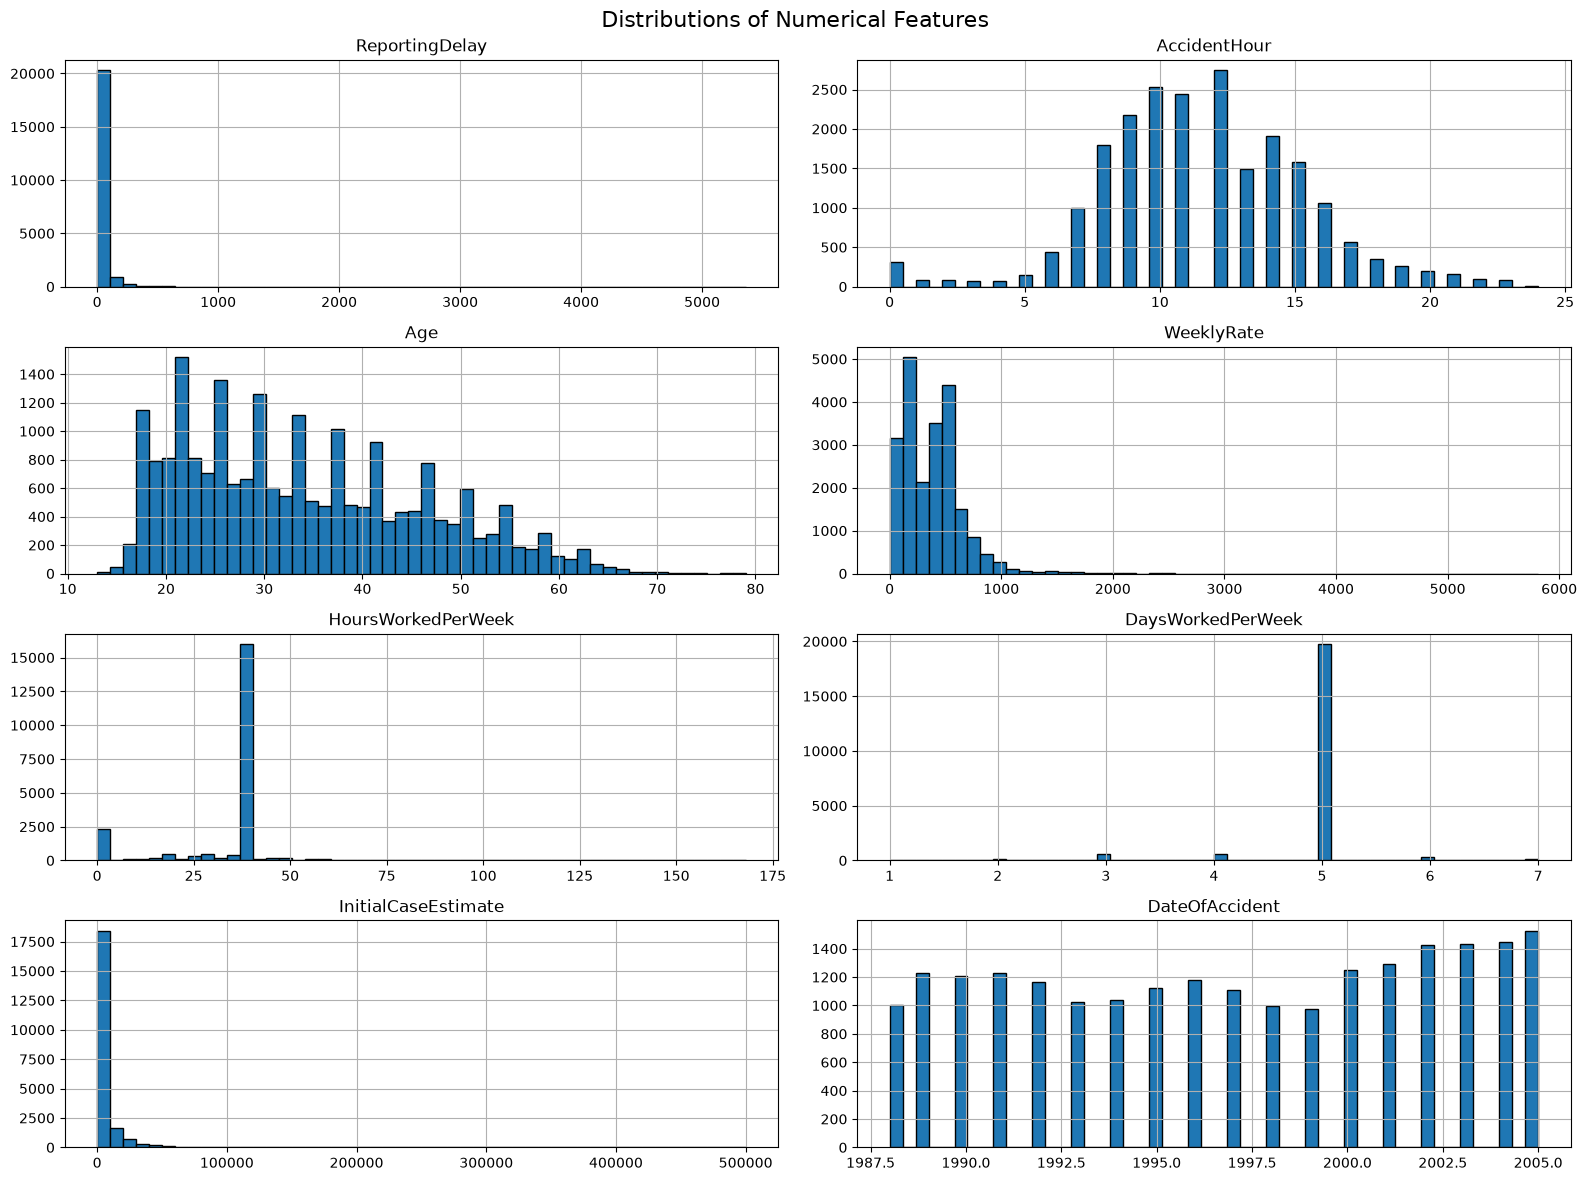

In [326]:
num_cols = [
    'ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate',
    'HoursWorkedPerWeek', 'DaysWorkedPerWeek',
    'InitialCaseEstimate', 'DateOfAccident'
]

# Create a copy for visualization
plot_df = df[num_cols].copy()

# Convert accident date to year for visualization
plot_df['DateOfAccident'] = plot_df['DateOfAccident'].dt.year

# Plot all histograms together
plot_df.hist(
    figsize=(16, 12),
    bins=50,
    layout=(4, 2),
    edgecolor='black'
)

plt.suptitle('Distributions of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

- Reporting delay is strongly right skewed.
- AccidentHour is almost normal.
- Age is right skewed.
- WeeklyRate is right skwewed.
- HoursWorkedPerWeek, most observations are concentrated around 38–40 hours per week.
- DaysWorkedPerWeek, most observations are concentrated at five days per week.
- InitialCaseEstimate is strongly right skewed.
- Date of accident is somehow normal.

## Visualizing the categorical columns

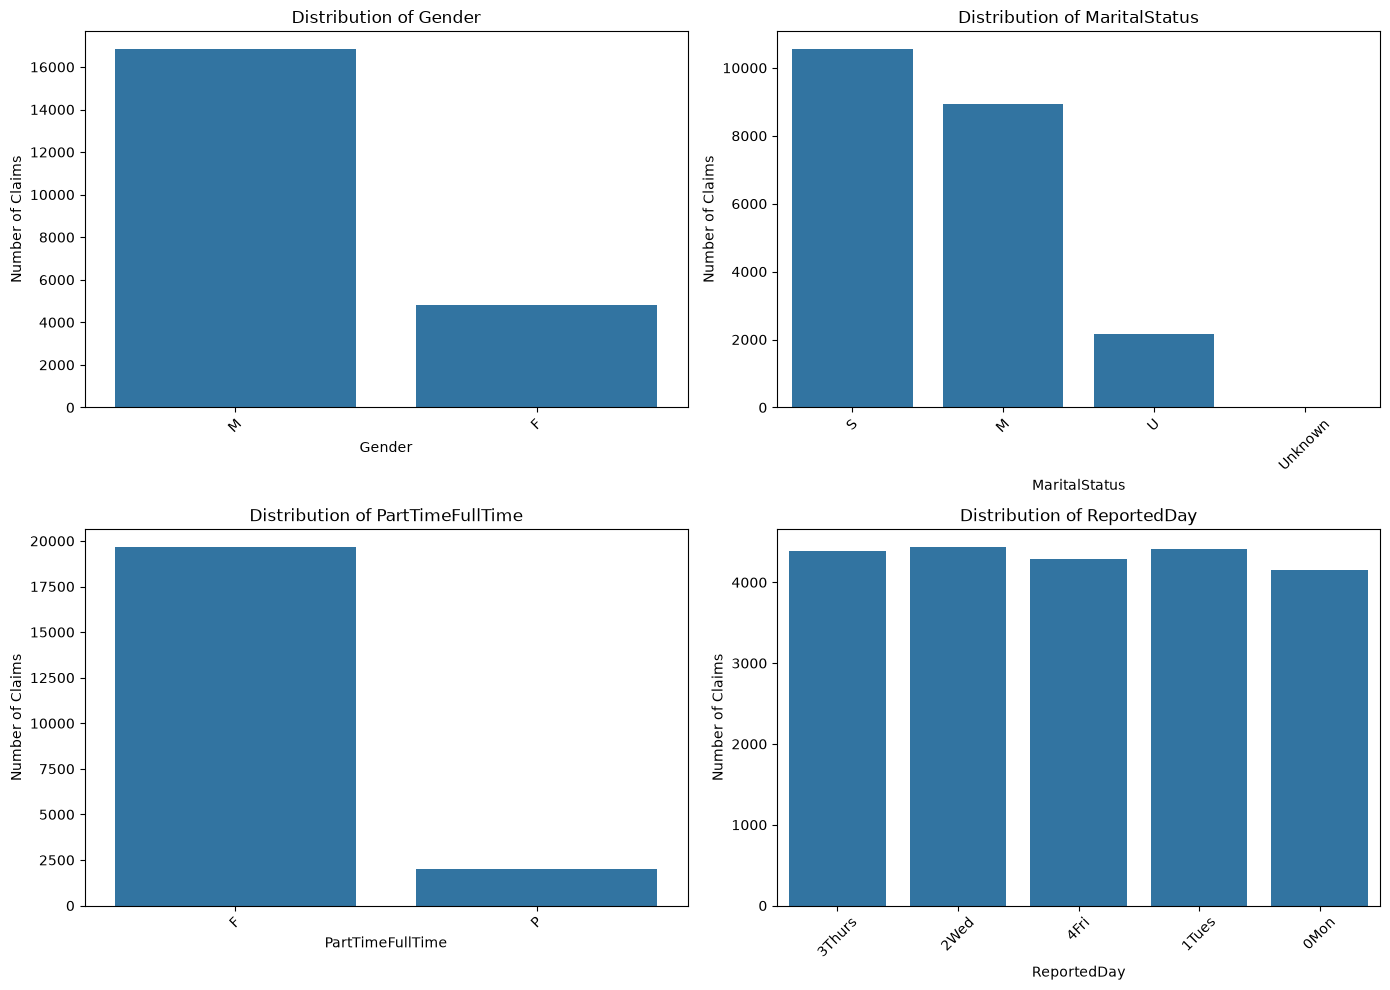

In [327]:
cat_cols = [
    'Gender',
    'MaritalStatus',
    'PartTimeFullTime',
    'ReportedDay'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Number of Claims')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

- Male are more compared to female.
- Single people are leading, followed by Married and lastly U (unknown)
- Full time employees are so many compared to part-time employees.
- The distribution of reportedDays is almost equal

In [328]:
df['MaritalStatus'].value_counts(dropna=False)

MaritalStatus
S          10549
M           8947
U           2150
Unknown       22
Name: count, dtype: int64

### Correlation heatmap

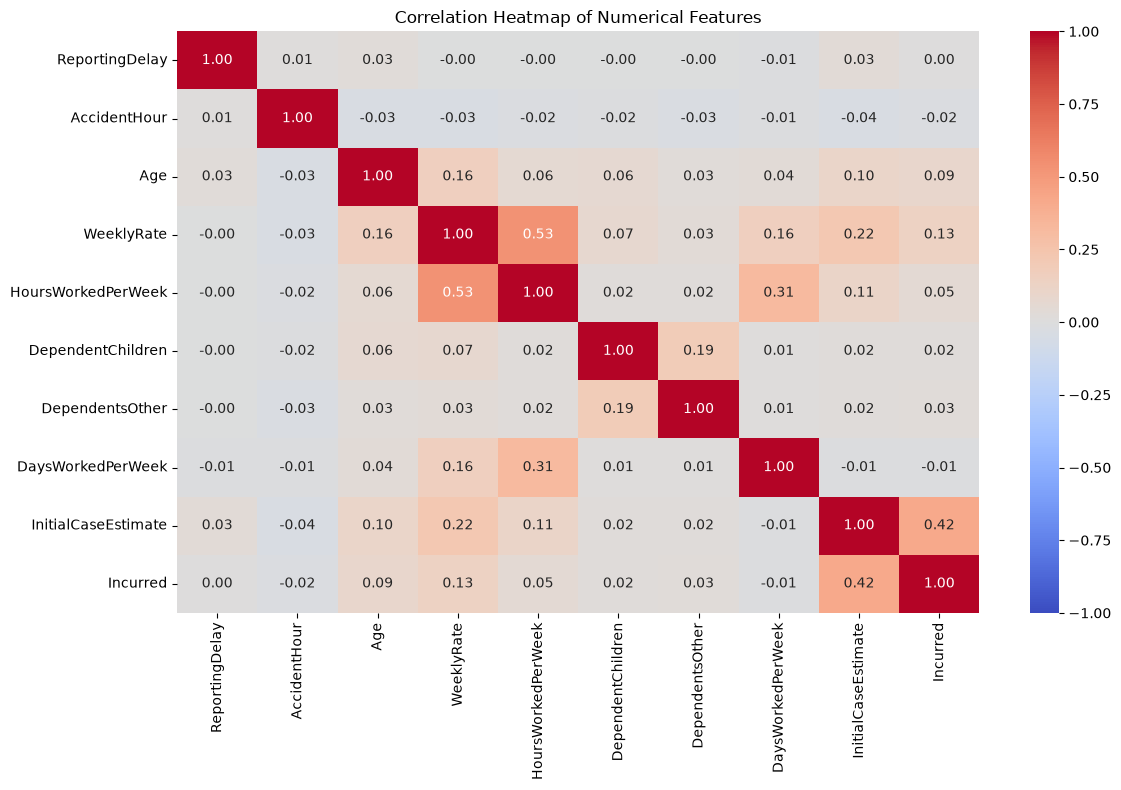

In [329]:
# Select numerical columns only
num_df = df.select_dtypes(include='number')

# Calculate correlations
corr = num_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

## VIF for multicollinearity.
- VIF = 1: no multicollinearity
- VIF </= 5: Moderate multicollinearity
- VIF > 5 (or 10): High multicollinearity

In [330]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical predictor variables
vif_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'InitialCaseEstimate'
]

# Prepare data for VIF
X_vif = df[vif_cols].dropna()

# Calculate VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data = vif_data.sort_values('VIF', ascending=False)
vif_data.round(2)

,Feature,VIF
4,HoursWorkedPerWeek,1.52
3,WeeklyRate,1.49
7,DaysWorkedPerWeek,1.11
8,InitialCaseEstimate,1.06
5,DependentChildren,1.05
6,DependentsOther,1.04
2,Age,1.04
1,AccidentHour,1.00
0,ReportingDelay,1.00


ReportingDelay and AccidentHour have almost no multicollinearity, while the rest have a low multicollinearity

## Outlier Treatment

In [331]:
numerical_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'InitialCaseEstimate',
    'Incurred'
]

outlier_results = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage (%)': len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary.round(2)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,ReportingDelay,-28.00,84.00,2042,9.42
1,AccidentHour,1.50,21.50,584,2.70
2,Age,-4.50,71.50,12,0.06
3,WeeklyRate,-250.00,950.00,572,2.64
4,HoursWorkedPerWeek,35.00,43.00,5165,23.84
5,DependentChildren,0.00,0.00,1267,5.85
6,DependentsOther,0.00,0.00,172,0.79
7,DaysWorkedPerWeek,5.00,5.00,1934,8.93
8,InitialCaseEstimate,-10000.00,18000.00,1924,8.88
9,Incurred,-2288.16,4294.27,3397,15.68


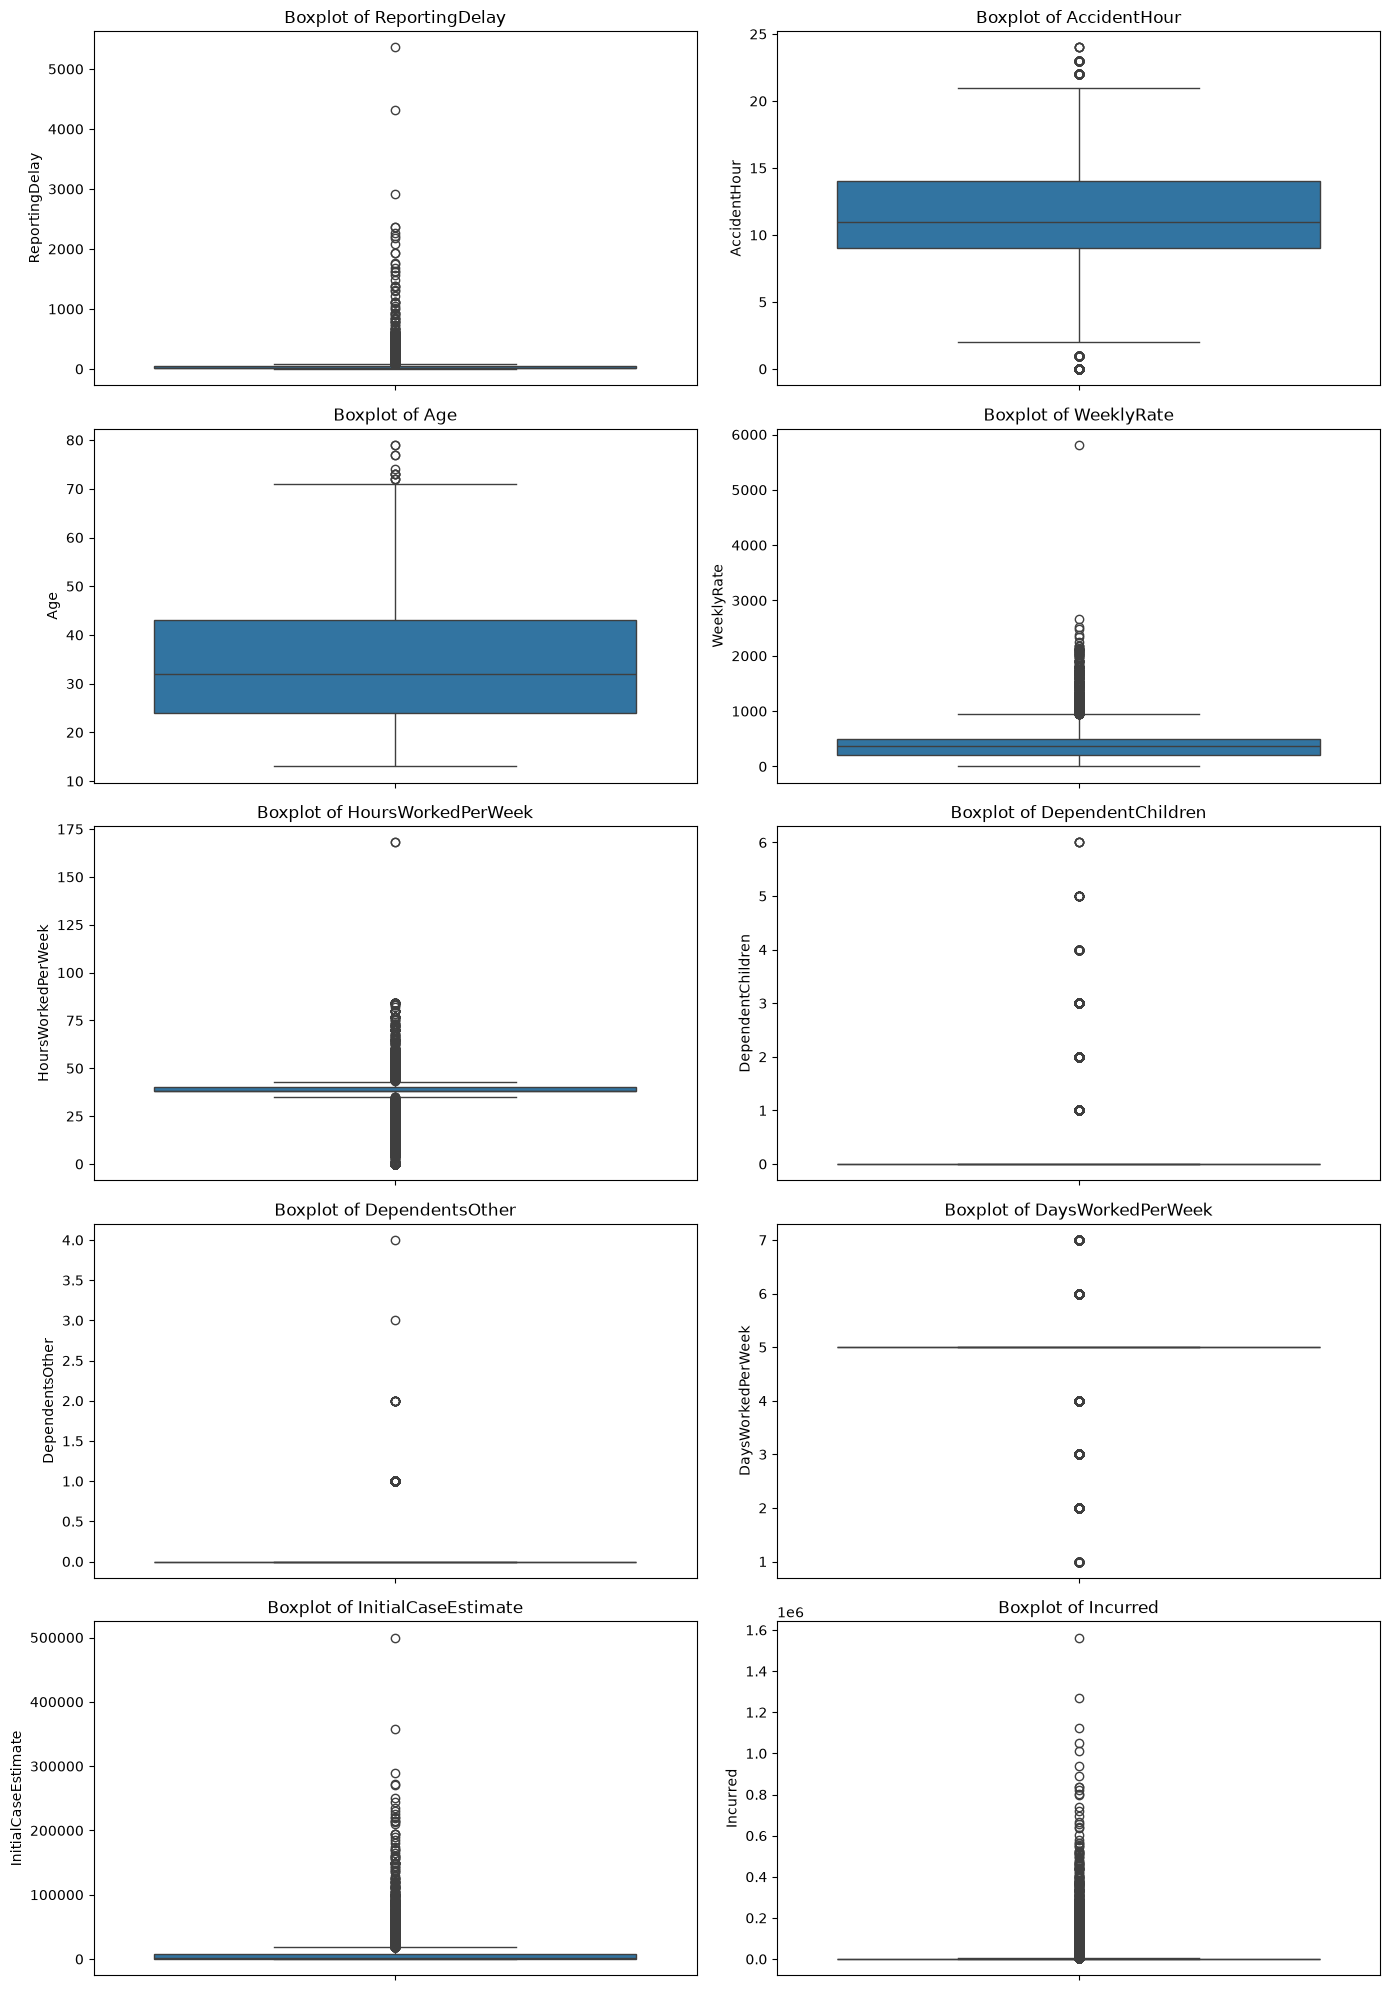

In [332]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

The boxplots reveal potential outliers in several numerical features, particularly ReportingDelay, WeeklyRate, HoursWorkedPerWeek, InitialCaseEstimate and Incurred. Several features, including the number of dependants and days worked per week, are naturally discrete and concentrated around particular values.

Outlier detection alone is not sufficient reason to delete observations hence the next step is to investigate implausible values and distinguish genuine extreme observations from data errors. Since Incurred is the target for claim severity prediction, unusually high claim amounts should be retained unless there is evidence that they are incorrect. If the target is later converted into low, medium and high severity classes, these extreme amounts will also influence the choice of severity thresholds.

The boxplots for DependentChildren and DependentsOther look unusual because these are count variables with many zeros. The IQR method flags legitimate nonzero values simply because most observations are zero. This does not mean those records are erroneous.

### Investigating AccidentHour

In [333]:
print("Minimum:", df['AccidentHour'].min())
print("Maximum:", df['AccidentHour'].max())

df.loc[
    (df['AccidentHour'] < 0) | (df['AccidentHour'] > 23),
    ['AccidentHour', 'DateOfAccident', 'ClaimDescription']
]

Minimum: 0
Maximum: 24


,AccidentHour,DateOfAccident,ClaimDescription
6421,24,1988-02-27,STRUCK METAL BAR STRAIN RIGHT SHOULDER INJURY
10688,24,1994-06-08,HIT ARM ON HAND LACERATION LEFT LOWER LEFT HAND
12027,24,1994-02-20,FELL FROM MACHINE LACERATION TO RIGHT ELBOW
19938,24,2003-08-04,SLIPPED KNIFE LACERATED LEFT FINGER


In the conventional 24-hour clock, valid hour values are 0–23, so 24 is outside the expected range.

 The observations have an `AccidentHour` value of 24. Since the available dataset documentation does not clarify the meaning of this value, the observations will be retained during EDA without modification. Their treatment will be reviewed during preprocessing to avoid making unsupported assumptions or unnecessarily removing data.

### Investigating WeeklyRate

In [334]:
Q1 = df['WeeklyRate'].quantile(0.25)
Q3 = df['WeeklyRate'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:", (df['WeeklyRate'] > upper_bound).sum())

df.loc[
    df['WeeklyRate'] > upper_bound,
    ['WeeklyRate', 'Age', 'HoursWorkedPerWeek',
     'PartTimeFullTime', 'InitialCaseEstimate', 'Incurred']
].sort_values('WeeklyRate', ascending=False).head(15)

Upper IQR bound: 950.0
Outlier count: 572


,WeeklyRate,Age,HoursWorkedPerWeek,PartTimeFullTime,InitialCaseEstimate,Incurred
7163,5811.30,59,65.00,F,20000,5487.785455
4033,2674.00,58,56.00,F,10000,2772.844053
10900,2522.03,24,56.00,F,990,406.359345
13591,2487.00,48,38.00,F,56625,639076.468900
8727,2380.93,24,56.00,F,440,206.843762
10475,2335.00,39,84.00,F,12000,2619.844308
16043,2246.00,25,59.00,F,55000,3297.121061
1444,2178.90,39,30.00,F,1000,1227.868896
21009,2171.32,52,54.00,F,700,230.864977
6027,2168.56,54,40.00,F,500,237.940682


Outliers will be kept since they may represent legitimate observations thus scaling (Robustscaler) will be considered during the preprocessing step

### Investigating InitialCaseEstimate

In [335]:
Q1 = df['InitialCaseEstimate'].quantile(0.25)
Q3 = df['InitialCaseEstimate'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:",
      (df['InitialCaseEstimate'] > upper_bound).sum())

df.loc[
    df['InitialCaseEstimate'] > upper_bound,
    ['InitialCaseEstimate', 'Incurred',
     'ClaimDescription', 'ReportingDelay']
].sort_values('InitialCaseEstimate', ascending=False).head(15)

Upper IQR bound: 18000.0
Outlier count: 1924


,InitialCaseEstimate,Incurred,ClaimDescription,ReportingDelay
4002,500000,4.599808e+05,BENDING CLEANING STRAIN LOWER BACK STRAIN LOWE...,20
8991,358000,3.963779e+05,LIFTING LOWER BACK STRAIN,94
591,290000,4.755062e+05,LIFTING REPETITIVE STRAIN BACK STRAIN LOWER BA...,40
6250,272000,1.563323e+06,FELL DOWN LOWER BACK LOWER BACK PAIN,25
7702,270000,3.963779e+05,FELL OFF LADDER BACK STRAIN RIGHT SHOULDER STRAIN,13
15479,250297,5.083576e+04,LIFTING CHILD STRAIN BACK STRAIN UPPER BACK ST...,15
7128,245000,8.253917e+03,FELL DOWN STAIRS STRAIN LEFT FINGERS,28
11562,235000,3.657718e+04,LIFTING STRAIN RIGHT KNEE,54
20412,230069,2.682134e+04,STRUCK FORKLIFT LOW BACK STRAIN,193
15047,225000,6.025641e+05,LIFTING RESIDENT LOWER BACK INJURY,49


The InitialCaseEstimate variable has 1,924 observations above the upper IQR bound of 18,000. These observations are flagged as potential outliers, but they will be retained pending further investigation because high initial claim estimates may be legitimate. Their distribution and relationship with the Incurred target will be examined before deciding on any preprocessing

Some claims have high initial estimates but much lower Incurred values. This is worth exploring, as the initial estimate may not match the final cost.

### Scatter plot for InitialCaseEstimate vs. Incurred 

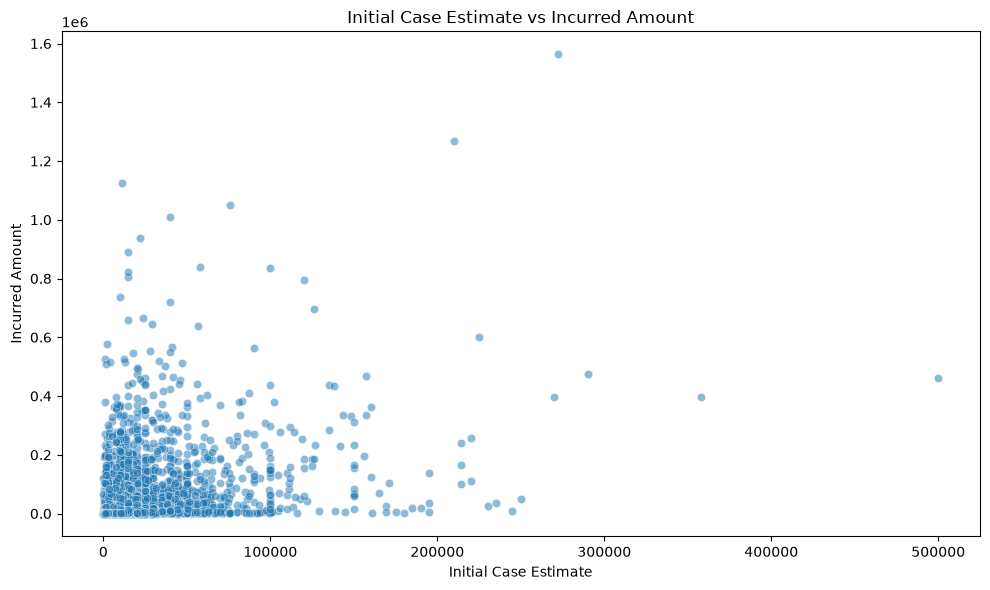

In [336]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='InitialCaseEstimate',
    y='Incurred',
    alpha=0.5
)

plt.title('Initial Case Estimate vs Incurred Amount')
plt.xlabel('Initial Case Estimate')
plt.ylabel('Incurred Amount')
plt.tight_layout()
plt.show()

- Both cases have both a low initial estimate and a low final incurred amount. 
- There are cases that were estimated very low but ended up costing a massive amount (the vertical outliers)
- 

### Investigating Incurred

In [337]:
Q1 = df['Incurred'].quantile(0.25)
Q3 = df['Incurred'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:", (df['Incurred'] > upper_bound).sum())

df.loc[
    df['Incurred'] > upper_bound,
    ['Incurred', 'InitialCaseEstimate', 'ClaimDescription',
     'Age', 'ReportingDelay']
].sort_values('Incurred', ascending=False).head(15)

Upper IQR bound: 4294.26682875
Outlier count: 3397


,Incurred,InitialCaseEstimate,ClaimDescription,Age,ReportingDelay
6250,1.563323e+06,272000,FELL DOWN LOWER BACK LOWER BACK PAIN,46,25
4854,1.269778e+06,210000,LIFTING LOWER BACK STRAIN LOWER BACK STRAIN,41,13
4316,1.124836e+06,11000,LIFTING BAGS BACK STRAIN LOWER BACK PAIN,49,28
3509,1.050411e+06,76000,SLIPPED ON STEP STRAIN RIGHT KNEE BACK STRAIN,41,6
8470,1.011132e+06,40000,STRUCK FALLING BOX LOWER BACK STRAIN LEFT LEG,33,8
7554,9.373632e+05,22000,LIFTING BOX STRAINED LOWER BACK STRAIN BACK,42,40
803,8.913606e+05,14500,TWISTED BACK STRAIN LOWER BACK STRAIN,26,63
6995,8.378862e+05,58115,LIFTING TRUCK BACK STRAIN LOWER BACK STRAIN,35,16
7304,8.345769e+05,100000,FALL OVER BACK STRAIN LOWER BACK INJURY,34,15
18000,8.234933e+05,15000,FELL FROM LADDER BACK SPRAIN,33,42


### Investigating DaysWorkedPerWeek

In [338]:
print(df['DaysWorkedPerWeek'].value_counts().sort_index())

DaysWorkedPerWeek
1       62
2      177
3      580
4      635
5    19734
6      360
7      120
Name: count, dtype: int64


# **Data Preprocessing**

# Creating a new target variable 'Severity'

Converting the continuous incurred amounts into three categories: Low, Medium and High severity through a process called *target variable descretisation or binning* (the process of converting a continuous numerical target variable into a finite set of discrete classes, bins or categories) since there is an abscence of established cost thresholds. Creation of a new column named "severity' and then categorize the thresholds into 33rd and 67th percentiles to divide into the three groups such that: claims below 33rd percentile are low severity, claims above 33rd but below 67th percentile are medium severity and lastly, claims above the 67th percentile are high severity. And also create some class balance.

In [339]:
# Checking Incurred distribution
df['Incurred'].describe(percentiles=[0.33, 0.50, 0.67])

count    2.166800e+04
mean     9.630120e+03
std      4.704018e+04
min      2.220000e-15
33%      2.484248e+02
50%      4.958777e+02
67%      1.121230e+03
max      1.563323e+06
Name: Incurred, dtype: float64

In [340]:
# Calculate the severity thresholds
lower_threshold = df['Incurred'].quantile(0.33)
upper_threshold = df['Incurred'].quantile(0.67)

print("Low severity upper limit:", lower_threshold)
print("Medium severity upper limit:", upper_threshold)

Low severity upper limit: 248.42475000000013
Medium severity upper limit: 1121.22955804


In [341]:
# Creating severity categories
df['Severity'] = np.select(
    [
        df['Incurred'] <= lower_threshold,
        df['Incurred'] <= upper_threshold
    ],
    [
        'Low',
        'Medium'
    ],
    default='High'
)

In [342]:
# Check resulting classes
print(df['Severity'].value_counts())

print("\nClass percentages:")
print((df['Severity'].value_counts(normalize=True) * 100).round(2))

Severity
Medium    7366
Low       7151
High      7151
Name: count, dtype: int64

Class percentages:
Severity
Medium    33.99
Low       33.00
High      33.00
Name: proportion, dtype: float64


The classes are nearly equally represented but medium has slightly more claims.

In [343]:
df.head(30)

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred,Severity
0,15,11,28,500.00,M,S,44.0,0,0,F,5,2005-10-05,STRUCK SCAFFOLDING STRAIN LOWER BACK,3Thurs,9500,151.254501,Low
1,22,5,29,500.00,M,S,38.0,0,0,F,5,2003-10-28,STRUCK KNIFE LACERATED LEFT THUMB,2Wed,11500,442.125024,Medium
2,22,7,28,197.37,M,M,16.0,0,0,P,3,2004-05-25,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,2Wed,8000,1494.490505,High
3,15,12,40,0.00,M,M,0.0,1,0,F,5,1994-07-21,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,4Fri,500,138.900000,Low
4,38,12,22,435.70,M,M,38.0,0,0,F,5,1992-06-09,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,4Fri,320,296.160000,Medium
5,55,7,18,263.45,F,U,40.0,0,0,F,5,1993-06-09,KNIFE SLIPPED CUT LEFT INDEX FINGER,1Tues,210,99.200000,Low
6,6,14,22,200.00,M,S,38.0,0,0,F,5,1995-04-20,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,2Wed,4000,154.625000,Low
7,105,7,17,0.00,M,S,0.0,0,0,F,5,1994-05-17,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,1Tues,500,252.500000,Medium
8,14,9,61,1446.00,M,M,60.0,0,0,F,5,2004-11-23,LIFTING PATIENT BACK PAIN,1Tues,5000,534.100143,Medium
9,10,12,62,461.90,M,M,25.0,0,0,P,4,1995-11-13,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,3Thurs,5000,766.425000,Medium


In [344]:
# Checking if creating 'Severity' created missing values
df['Severity'].isna().sum()

np.int64(0)

### Combining 'unknown' and 'U'

In [345]:
df['MaritalStatus'] = df['MaritalStatus'].replace({
    'U': 'Unknown',
    'Unknown': 'Unknown'
})

In [346]:
print(df['MaritalStatus'].value_counts())

MaritalStatus
S          10549
M           8947
Unknown     2172
Name: count, dtype: int64


### Research on:-
impact of creating severity column from incurred column only.
> - ANS: Think of it this way: you know the final incurred amount for historical claims, so you use it to label them Low, Medium or High. The model then learns from the other available information to predict the severity of a new claim. The model learns from the available features by learning patterns connecting the available features to the severity labels. For a new claim, it receives the description, age and other eligible features, then predicts Low, Medium or High. It does not need the new claim's final Incurred amount to make that prediction.

# Extracting keywords from 'ClaimDescription'

In [347]:
# checking few descriptions in order to build the keyword categories
df['ClaimDescription'].head(30)

0                  STRUCK SCAFFOLDING STRAIN LOWER BACK
1                     STRUCK KNIFE LACERATED LEFT THUMB
2     SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...
3     HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...
4     STRUCK FALLING OBJECT LACERATION RIGHT RING FI...
5                   KNIFE SLIPPED CUT LEFT INDEX FINGER
6     SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...
7           LIFTING METAL SHEETS STRAIN LOWER BACK PAIN
8                             LIFTING PATIENT BACK PAIN
9       SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE
10    SLIPPED CUTTING WITH KNIFE LACERATION RIGHT IN...
11                        LIFTING PIPE LOWER BACK LOWER
12              HIT IN STEEL LOWER BACK STRAIN AND KNEE
13    LIFTING RESIDENT LACERATION LEFT ARM LEFT SHOU...
14    STRUCK KNIFE LACERATION LEFT THUMB INJURY HAND...
15               FELL DOWN LOWER BACK STRAIN LOWER BACK
16           LIFTING HEAVY LIFTING BACK LEFT EYE INJURY
17           LIFTING BACK STRAIN LOWER BACK INJU

Common keywords:- 

- **How accident happened**: struck, fell, strained, slipped, lifting, caught, hit, falling , cutting, cut
- **Injury type**: strain, sprain, strained, laceration, lacerated, bruise, bruised, fracture, crush, injury, pain, cut
- **Body part**: back, shoulder, knee, thumb, finger, hand, arm, leg, wrist, neck, eye, ankle, groin, head



### Stemming vs. Lemmatization
- Stemming - is a rule-based text normalisation technique that reduces words to their root form by removing prefixes or suffixes such as -ing, -ed, -es
- Lemmatization -  is a linguistically driven text normalization technique that converts words into their base dictionary form, known as a lemma, by considering grammar, vocabulary and context.

# Using Lemmatization

In [348]:
# # installing packages
# %pip install nltk

In [349]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [350]:
from nltk.stem import WordNetLemmatizer
import re

lemmatizer = WordNetLemmatizer()

def lemmatize_description(description):
    words = re.findall(r'\b[a-zA-Z]+\b', str(description).lower())
    return " ".join(lemmatizer.lemmatize(word, pos='v') for word in words)

df['ClaimDescription_Lemmatized'] = df['ClaimDescription'].apply(
    lemmatize_description
)

df[['ClaimDescription', 'ClaimDescription_Lemmatized']].head(30)

,ClaimDescription,ClaimDescription_Lemmatized
0,STRUCK SCAFFOLDING STRAIN LOWER BACK,strike scaffold strain lower back
1,STRUCK KNIFE LACERATED LEFT THUMB,strike knife lacerate leave thumb
2,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,slip and hit strain leave shoulder injury leav...
3,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,hit fall door laceration leave shoulder injury...
4,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,strike fall object laceration right ring finger
5,KNIFE SLIPPED CUT LEFT INDEX FINGER,knife slip cut leave index finger
6,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,slip on steel beam lower back bruise knee liga...
7,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,lift metal sheet strain lower back pain
8,LIFTING PATIENT BACK PAIN,lift patient back pain
9,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,slip off truck bruise lower back right knee


- words have been lemmatized but 'left thumb' has been converted to 'leave thumb'
- laceration has not been converted to lacerate like the way lacerated was

# Using Stemming

In [351]:
import re
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

# Normalize important irregular terms before stemming
word_map = {
    'fell': 'fall',
    'fallen': 'fall',
    'struck': 'strike'
}

def stem_description(description):
    words = re.findall(r'\b[a-zA-Z]+\b', str(description).lower())

    words = [word_map.get(word, word) for word in words]

    return " ".join(stemmer.stem(word) for word in words)

df['ClaimDescription_Stemmed'] = df['ClaimDescription'].apply(
    stem_description
)

df[['ClaimDescription', 'ClaimDescription_Stemmed']].head(30)

,ClaimDescription,ClaimDescription_Stemmed
0,STRUCK SCAFFOLDING STRAIN LOWER BACK,strike scaffold strain lower back
1,STRUCK KNIFE LACERATED LEFT THUMB,strike knife lacer left thumb
2,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,slip and hit strain left shoulder injuri left ...
3,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,hit fall door lacer left shoulder injuri right...
4,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,strike fall object lacer right ring finger
5,KNIFE SLIPPED CUT LEFT INDEX FINGER,knife slip cut left index finger
6,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,slip on steel beam lower back bruis knee ligament
7,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,lift metal sheet strain lower back pain
8,LIFTING PATIENT BACK PAIN,lift patient back pain
9,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,slip off truck bruis lower back right knee


all words have been correctly standardized with the body parts, such as left thumb has been preserved. **Thus stemming will be chosen over lemmatization.**

### Applying TF-IDF (term frequency-inverse document frequency)
- fitted on training data only to prevent data leakage
> - It is a statistical method used in natural language processing and information retrieval to evaluate how important a word is to a document in relation to a larger collection of documents by measuring how often a word appears in a document (term frequency) and reduces the weight of common words across multiple documents while increasing the weight of rare words (Inverse Document Frequency)

In [352]:
# !pip install scikit-learn

In [353]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=500)

X_text = tfidf.fit_transform(df['ClaimDescription_Stemmed'])

print("TF-IDF matrix shape:", X_text.shape)

TF-IDF matrix shape: (21668, 495)


- Each row reps a claim, each column reps a word or term and each value reps how important that term is within a claim relative to the dataset

In [354]:
# Inspect the features
print("Number of text features:", len(tfidf.get_feature_names_out()))
print(tfidf.get_feature_names_out()[:30])

Number of text features: 495
['abdomin' 'abras' 'accid' 'ach' 'against' 'air' 'aircraft' 'alleg'
 'aluminium' 'amput' 'and' 'angl' 'ankl' 'anxieti' 'arm' 'arthralgia'
 'assault' 'assist' 'at' 'back' 'backho' 'backward' 'bag' 'baggag' 'ball'
 'bar' 'batteri' 'beam' 'bed' 'belt']


numerical input features that help the model learn patterns associated with claim severity.

### Inspect the TF-IDF matrix

In [355]:
# numerical values of the first 5 claims
tfidf_df = pd.DataFrame(
    X_text[:5].toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.iloc[:, :15]

,abdomin,abras,accid,ach,against,air,aircraft,alleg,aluminium,amput,and,angl,ankl,anxieti,arm
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.34139,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0


descriptions have been converted into numerical values correctly.

**NB**: Later, when we prepare the final model, we'll fit TF-IDF on the training descriptions only, then transform the test descriptions to prevent data leakage.

### Separate target vs. input features

In [356]:
df.columns

Index(['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender',
       'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren',
       'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek',
       'DateOfAccident', 'ClaimDescription', 'ReportedDay',
       'InitialCaseEstimate', 'Incurred', 'Severity',
       'ClaimDescription_Lemmatized', 'ClaimDescription_Stemmed'],
      dtype='str')

In [357]:
# Keep rows that have a valid target
model_df = df.dropna(subset=['Severity']).copy()

# Target variable
y = model_df['Severity']

# Input features: exclude targets and text columns
# X_nontext contains the candidate input features
X_nontext = model_df.drop(
    columns=[
        'Severity',
        'Incurred',
        'ClaimDescription',
        'ClaimDescription_Lemmatized',
        'ClaimDescription_Stemmed'
    ],
    errors='ignore'
)

print("Input features shape:", X_nontext.shape)
print("Target shape:", y.shape)

print("\nInput feature columns:")
print(X_nontext.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Input features shape: (21668, 14)
Target shape: (21668,)

Input feature columns:
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender', 'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek', 'DateOfAccident', 'ReportedDay', 'InitialCaseEstimate']

Target distribution:
Severity
Medium    7366
Low       7151
High      7151
Name: count, dtype: int64


We dropped ClaimDescription when separating the target and input features because machine learning models cannot directly work with raw text in the same way they work with numerical features.


In [358]:
# Check datatypes and missing values
# Check data types
print(X_nontext.dtypes)

# Check missing values
print("\nMissing values per feature:")
print(X_nontext.isnull().sum())

ReportingDelay                  int64
AccidentHour                    int64
Age                             int64
WeeklyRate                    float64
Gender                            str
MaritalStatus                     str
HoursWorkedPerWeek            float64
DependentChildren               int64
DependentsOther                 int64
PartTimeFullTime                  str
DaysWorkedPerWeek               int64
DateOfAccident         datetime64[us]
ReportedDay                       str
InitialCaseEstimate             int64
dtype: object

Missing values per feature:
ReportingDelay         0
AccidentHour           0
Age                    0
WeeklyRate             0
Gender                 0
MaritalStatus          0
HoursWorkedPerWeek     0
DependentChildren      0
DependentsOther        0
PartTimeFullTime       0
DaysWorkedPerWeek      0
DateOfAccident         0
ReportedDay            0
InitialCaseEstimate    0
dtype: int64


### Extract date features
> - Machine-learning models generally cannot use a raw datetime column directly, so we'll extract useful information from it.

In [359]:
# Extract useful information from DateOfAccident
X_nontext['AccidentYear'] = X_nontext['DateOfAccident'].dt.year
X_nontext['AccidentMonth'] = X_nontext['DateOfAccident'].dt.month
X_nontext['AccidentDayOfWeek'] = X_nontext['DateOfAccident'].dt.dayofweek

# Remove the original datetime column
X_nontext = X_nontext.drop(columns=['DateOfAccident'])

# Check the updated features
print(X_nontext.shape)
print(X_nontext.columns.tolist())

(21668, 16)
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender', 'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek', 'ReportedDay', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek']


# Encoding categorical features
- Use one-hot encoding because categorical features are nominal, meaning they have no natural order and prevent the model from interpreting them as ranked values.

In [360]:
# Identify categorical columns
categorical_cols = X_nontext.select_dtypes(
    include=['str', 'object', 'category']
).columns.tolist()

print("Categorical columns:", categorical_cols)

Categorical columns: ['Gender', 'MaritalStatus', 'PartTimeFullTime', 'ReportedDay']


In [361]:
# One-hot encode categorical features
X_nontext_encoded = pd.get_dummies(
    X_nontext,
    columns=categorical_cols,
    drop_first=False, 
    dtype=int
)

print("Shape before encoding:", X_nontext.shape)
print("Shape after encoding:", X_nontext_encoded.shape)

print("\nEncoded feature columns:")
print(X_nontext_encoded.columns.tolist())

Shape before encoding: (21668, 16)
Shape after encoding: (21668, 24)

Encoded feature columns:
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'DaysWorkedPerWeek', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek', 'Gender_F', 'Gender_M', 'MaritalStatus_M', 'MaritalStatus_S', 'MaritalStatus_Unknown', 'PartTimeFullTime_F', 'PartTimeFullTime_P', 'ReportedDay_0Mon', 'ReportedDay_1Tues', 'ReportedDay_2Wed', 'ReportedDay_3Thurs', 'ReportedDay_4Fri']


increased columns from 16 to 24

# Train/Test Split

In [362]:
# checking date range
print("Earliest accident date:", model_df['DateOfAccident'].min())
print("Latest accident date:", model_df['DateOfAccident'].max())

Earliest accident date: 1988-01-02 00:00:00
Latest accident date: 2005-12-31 00:00:00


# Create a chronological train-test split
- Simulate real-world use: In practice, a model is trained on historical claims and use it to assess new claims arriving later.

Reasons for a chronological train-test split:
- Reduce temporal leakage: A random split could place older and newer claims in both training and testing sets, making the evaluation less representative of predicting future claims.
- Evaluate generalisation over time: The model learns from claims up to July 2022 and is tested on claims from July 2022 onward, allowing us to assess performance on later claims.
- The chronological split is appropriate since the intended use is to evaluate how well the model would perform on prediting the severity of claims from a later period using historical claims, which allows to train on earlier claims and test on later claims.
- A random split would have placed claims from later and earlier years in tha tarining set which would have given overly optimistic results.

In [363]:
# Get unique accident dates in chronological order
unique_dates = model_df['DateOfAccident'].sort_values().unique()

# Select the date boundary
split_point = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_point]

# Split so each date belongs to only one set
train_mask = model_df['DateOfAccident'] < split_date
test_mask = model_df['DateOfAccident'] >= split_date

# Create training and testing sets
X_train = X_nontext_encoded.loc[model_df.index[train_mask]]
X_test = X_nontext_encoded.loc[model_df.index[test_mask]]

y_train = model_df.loc[train_mask, 'Severity']
y_test = model_df.loc[test_mask, 'Severity']

print("Split date:", split_date)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Last training date:",
      model_df.loc[X_train.index, 'DateOfAccident'].max())
print("First testing date:",
      model_df.loc[X_test.index, 'DateOfAccident'].min())

Split date: 2002-07-22 00:00:00
Training features: (16615, 24)
Testing features: (5053, 24)
Last training date: 2002-07-20 00:00:00
First testing date: 2002-07-22 00:00:00


- 80% = training
- 20 % = testing

Important: This split is for the non-text features only. We'll apply the same split to the claim descriptions before fitting TF-IDF, so the vocabulary and feature weights are learned from training claims rather than the entire dataset

In [364]:
# Let's check whether the split should keep entire dates together to avoid this overlap.
print("Last training date:", model_df.loc[X_train.index, 'DateOfAccident'].max())
print("First testing date:", model_df.loc[X_test.index, 'DateOfAccident'].min())

print(
    "Same date in both sets:",
    model_df.loc[X_train.index, 'DateOfAccident'].max()
    == model_df.loc[X_test.index, 'DateOfAccident'].min()
)

Last training date: 2002-07-20 00:00:00
First testing date: 2002-07-22 00:00:00
Same date in both sets: False


 2003-01-17 appeared at the end of training and the beginning of testing, so claims from the same date may be in both sets. just confirming if there are any overlapping dates

## Prepare text data for TF-IDF

In [365]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Align descriptions with the existing chronological split
text_train = model_df.loc[X_train.index, 'ClaimDescription_Stemmed']
text_test = model_df.loc[X_test.index, 'ClaimDescription_Stemmed']

# Fit TF-IDF only on training descriptions
tfidf = TfidfVectorizer(max_features=500)

X_train_text = tfidf.fit_transform(text_train)
X_test_text = tfidf.transform(text_test)

print("Training text shape:", X_train_text.shape)
print("Testing text shape:", X_test_text.shape)

Training text shape: (16615, 465)
Testing text shape: (5053, 465)


# **Feature Scaling**

In [366]:
print(X_train.columns.tolist())

['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'DaysWorkedPerWeek', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek', 'Gender_F', 'Gender_M', 'MaritalStatus_M', 'MaritalStatus_S', 'MaritalStatus_Unknown', 'PartTimeFullTime_F', 'PartTimeFullTime_P', 'ReportedDay_0Mon', 'ReportedDay_1Tues', 'ReportedDay_2Wed', 'ReportedDay_3Thurs', 'ReportedDay_4Fri']


In [367]:
# Scaling using robust scaler because reporting delay and weeklyrate contain extreme values
from sklearn.preprocessing import RobustScaler

# Continuous numerical features to scale
numeric_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'AccidentYear',
    'AccidentMonth',
    'AccidentDayOfWeek'
]

# Create copies so the original data remains unchanged
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit scaler on training data only
scaler = RobustScaler()

X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

# Use the same scaler to transform test data
X_test_scaled[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (16615, 24)
Scaled testing shape: (5053, 24)


## Combine text and non-text features and split

In [368]:
from scipy.sparse import hstack, csr_matrix

# Convert scaled structured features to sparse matrices
X_train_structured = csr_matrix(X_train_scaled.to_numpy(dtype=float))
X_test_structured = csr_matrix(X_test_scaled.to_numpy(dtype=float))

# Combine structured and TF-IDF features
X_train_combined = hstack(
    [X_train_structured, X_train_text],
    format='csr'
)

X_test_combined = hstack(
    [X_test_structured, X_test_text],
    format='csr'
)

print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape:", X_test_combined.shape)

Combined training shape: (16615, 489)
Combined testing shape: (5053, 489)


489 total features: 24 structured features + 465 text features.

# **Feature Selection**
- It shows how much the model relies on features, it does not prove that a feature causes a claim to be more severe.

### Random Forest

In [369]:
from sklearn.ensemble import RandomForestClassifier

# ranks features by importance

# Combine feature names in the same order as the combined matrix
feature_names = (
    X_train.columns.tolist()
    + tfidf.get_feature_names_out().tolist()
)

# Check that feature names match the combined data
print("Number of feature names:", len(feature_names))
print("Number of combined features:", X_train_combined.shape[1])

# Train a Random Forest for feature importance
rf_selector = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_selector.fit(X_train_combined, y_train)

# Rank features by importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_selector.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Display the 20 most important features
feature_importance.head(20)

Number of feature names: 489
Number of combined features: 489


,Feature,Importance
0,InitialCaseEstimate,0.104066
1,WeeklyRate,0.048877
2,Age,0.043277
3,ReportingDelay,0.036826
4,AccidentYear,0.032783
5,AccidentHour,0.031345
6,AccidentMonth,0.029921
7,HoursWorkedPerWeek,0.028922
8,strain,0.027141
9,back,0.025274


- InitialCaseEstimate (0.1041): the most important feature in this ranking, contributing about 10.41% of the model's total feature importance.
- WeeklyRate and Age: also contribute useful predictive information.
- ReportingDelay and AccidentYear: suggest that reporting behaviour and the timing of accidents may help distinguish severity classes.
- Text features such as strain, back, lacer, strike and finger indicate that the words in claim descriptions provide potentially useful information.

In particular, check InitialCaseEstimate: if it is not available at the point when a claim needs to be triaged, using it could cause information leakage and make your model appear more useful than it would be in practice.

### Drop 'InitialCaseEstimate' 
- The project uses initial claim description and information available when a claim is first reported to predict its eventual sevrity if low, medium or high.
> - Advantage: helps with prioritization of claims early.
> - Limitation: model must predict severity before the final cost is known.

In [370]:
from scipy.sparse import hstack, csr_matrix

# Remove InitialCaseEstimate from structured features
X_train_no_estimate = X_train_scaled.drop(columns=['InitialCaseEstimate'])
X_test_no_estimate = X_test_scaled.drop(columns=['InitialCaseEstimate'])

# Convert structured features to sparse matrices
X_train_structured = csr_matrix(
    X_train_no_estimate.to_numpy(dtype=float)
)
X_test_structured = csr_matrix(
    X_test_no_estimate.to_numpy(dtype=float)
)

# Combine structured and TF-IDF text features
X_train_combined = hstack(
    [X_train_structured, X_train_text],
    format='csr'
)

X_test_combined = hstack(
    [X_test_structured, X_test_text],
    format='csr'
)

print("Training shape:", X_train_combined.shape)
print("Testing shape:", X_test_combined.shape)

Training shape: (16615, 488)
Testing shape: (5053, 488)


# **Modelling**

## 1. Random Forest Model

In [371]:
# train the random forest model
from sklearn.ensemble import RandomForestClassifier

# Initialize the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_combined, y_train) # learns patterns from the training claims

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test_combined) # predicts severity category of each test claim

print("Random Forest training complete.")
print("Number of predictions:", len(y_pred_rf))

Random Forest training complete.
Number of predictions: 5053


In [372]:
# evaluating the model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

# Precision, recall and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Numerical confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm)


Accuracy: 0.5489808034830793

Classification Report:
              precision    recall  f1-score   support

        High       0.66      0.74      0.70      2278
         Low       0.40      0.37      0.38       993
      Medium       0.45      0.41      0.43      1782

    accuracy                           0.55      5053
   macro avg       0.51      0.50      0.50      5053
weighted avg       0.54      0.55      0.54      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 364  418  211]
 [ 410  732  640]
 [ 126  474 1678]]


**NB:** use Recall (esp for high severity class) because missing a genuinely high severity claim could be more costly than incorrectly flagging a low severity claim.

- Accuracy of 54.78%, meaning the model classifies appropriately 55 out of every 100 test claim.
- High severity: Recall is 74%, meaning the model identifies approximately 74% of genuinely High-severity claims and misses about 26%.
- Low severity: Recall is only 36%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 41%, meaning many Medium claims are being assigned another category.

Confusion Matrix
- Low Severity: The model correctly identified 361 Low-severity claims. It incorrectly classified 420 as Medium and 212 as High. This is the weakest class in terms of recall.
- Medium Severity: The model correctly identified 728 Medium-severity claims. However, 414 were classified as Low and 640 as High.
- High Severity: The model correctly identified 1,679 High-severity claims. It misclassified 475 as Medium and 124 as Low.

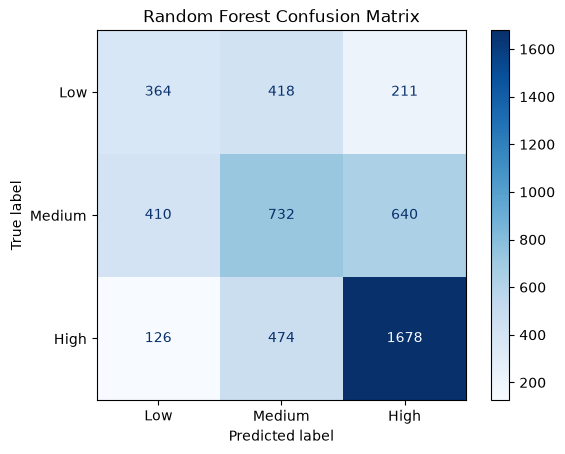

In [373]:
# visualizing confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Random Forest Confusion Matrix")
plt.show()


## 2. XGBoost

In [374]:
import xgboost as xgb

In [375]:
# Train the xgboost model

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Convert severity labels into numeric labels for XGBoost
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Initialize the Gradient Boosting model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6, # limit of every tree
    learning_rate=0.1,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_combined, y_train_encoded)

# Predict severity
y_pred_xgb_encoded = xgb_model.predict(X_test_combined)

# Convert predictions back to severity labels
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded.astype(int)
)

print("XGBoost training complete.")
print("Number of predictions:", len(y_pred_xgb))


XGBoost training complete.
Number of predictions: 5053


In [376]:
# Evaluate the model

# Evaluate accuracy
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=['High', 'Low', 'Medium', ],
    zero_division=0
))

# Numerical confusion matrix
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm_xgb)


XGBoost Accuracy: 0.5687710271126064

Classification Report:
              precision    recall  f1-score   support

        High       0.66      0.76      0.71      2278
         Low       0.47      0.31      0.38       993
      Medium       0.47      0.47      0.47      1782

    accuracy                           0.57      5053
   macro avg       0.53      0.51      0.52      5053
weighted avg       0.56      0.57      0.56      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 311  456  226]
 [ 285  841  656]
 [  66  490 1722]]


- Accuracy of 56.87%, meaning the model classifies appropriately 56 out of every 100 test claim.
- High severity: Recall is 76%, meaning the model identifies approximately 76% of genuinely High-severity claims and misses about 24%.
- Low severity: Recall is only 31%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 46%, meaning many Medium claims are being assigned another category.

Confusion Matrix
- Low severity: Correctly classified 306 of 993 claims (30.8%). The model often predicts these as Medium.
- Medium severity: Correctly classified 821 of 1,782 claims (46.1%). However, 657 are incorrectly classified as High.
- High severity: Correctly classified 1,731 of 2,278 claims (76.0%). Only 63 are incorrectly classified as Low, while 484 are classified as Medium.

**Note:** XGBoost is the better performing model especially while identifying high severity claims

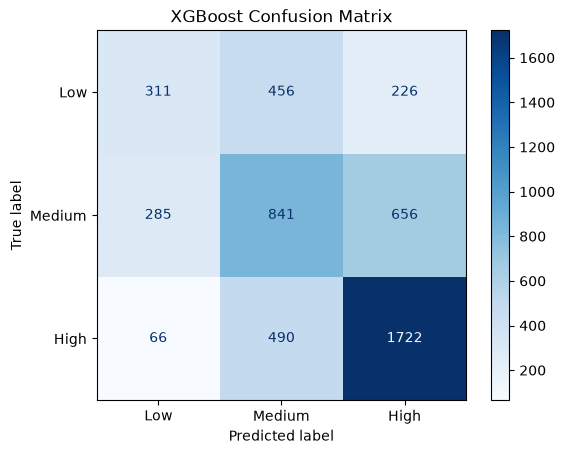

In [377]:
# confusion matrix visualization

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("XGBoost Confusion Matrix")
plt.show()


# 3. Multilayer Perceptron — MLP

## Feature Scaling 
- Scaling helps the neural network learn effectively when features have very different numerical ranges
- using Standardscaler on structured features because MLP neural networks generally perform better when numerical features are standardized to have a mean of 0 and a standard deviation of 1, helping prevent features with larger numerical ranges from dominating the learning process.

In [378]:

from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, csr_matrix

# Scale the structured features using training data only
scaler = StandardScaler()

X_train_structured_scaled = scaler.fit_transform(
    X_train_no_estimate
)

X_test_structured_scaled = scaler.transform(
    X_test_no_estimate
)

# Combine scaled structured features with TF-IDF features
X_train_mlp = hstack(
    [csr_matrix(X_train_structured_scaled), X_train_text],
    format='csr'
)

X_test_mlp = hstack(
    [csr_matrix(X_test_structured_scaled), X_test_text],
    format='csr'
)

print("MLP training shape:", X_train_mlp.shape)
print("MLP testing shape:", X_test_mlp.shape)


MLP training shape: (16615, 488)
MLP testing shape: (5053, 488)


In [379]:
# Train MLP neural network
from sklearn.neural_network import MLPClassifier

# Initialize the MLP neural network
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100, 50), # tow hidden layers with 100 neurons and 50 neurons
    activation='relu', # help network learn non-linear patterns
    solver='adam', # adjusts the network's weights during training
    max_iter=300,
    early_stopping=True, # stop training if validation performance stops improving
    random_state=42
)

# Train the model
mlp_model.fit(X_train_mlp, y_train)

# Predict claim severity
y_pred_mlp = mlp_model.predict(X_test_mlp)

print("MLP training complete.")
print("Number of predictions:", len(y_pred_mlp))


MLP training complete.
Number of predictions: 5053


In [380]:
# Evaluate the MLP model

# Calculate accuracy
print("MLP Accuracy:", accuracy_score(y_test, y_pred_mlp))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_mlp,
    labels=['High','Low', 'Medium', ],
    zero_division=0
))

# Numerical confusion matrix
cm_mlp = confusion_matrix(
    y_test,
    y_pred_mlp,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm_mlp)


MLP Accuracy: 0.5713437561844449

Classification Report:
              precision    recall  f1-score   support

        High       0.63      0.84      0.72      2278
         Low       0.46      0.31      0.37       993
      Medium       0.50      0.37      0.42      1782

    accuracy                           0.57      5053
   macro avg       0.53      0.51      0.50      5053
weighted avg       0.55      0.57      0.55      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 309  385  299]
 [ 297  654  831]
 [  72  282 1924]]


- Accuracy of 57.13%, meaning the model classifies appropriately 57 out of every 100 test claim.
- High severity: Recall is 84%, meaning the model identifies approximately 84% of genuinely High-severity claims and misses about 16%.
- Low severity: Recall is only 31%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 37%, meaning many Medium claims are being assigned another category.

Confusion Matrix
- Low Severity: The model correctly identified 309 Low-severity claims. It incorrectly classified 385 as Medium and 299 as High. This is the weakest class in terms of recall.
- Medium Severity: The model correctly identified 654 Medium-severity claims. However, 297 were classified as Low and 831 as High.
- High Severity: The model correctly identified 1,924 High-severity claims. It misclassified 282 as Medium and 72 as Low. This is the strongest class in terms of recall.

**Note:** The MLP is effective at identifying High-cost claims, which could be useful for prioritising claims for review. However, its weaker performance on Low and Medium claims means it should not be treated as a reliable standalone triage system.

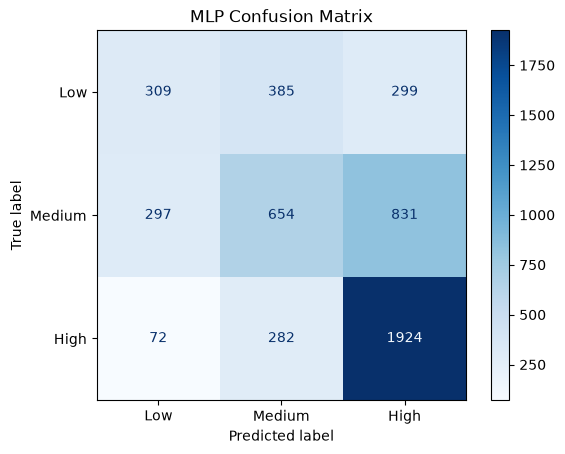

In [381]:
# confusion matrix visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("MLP Confusion Matrix")
plt.show()


### Final Model Comparison

In [382]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Compare the three models
models = {
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'MLP Neural Network': y_pred_mlp
}

results = []

for model_name, y_pred in models.items():
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Low Recall': recall_score(
            y_test, y_pred, labels=['Low'], average=None
        )[0],
        'Medium Recall': recall_score(
            y_test, y_pred, labels=['Medium'], average=None
        )[0],
        'High Recall': recall_score(
            y_test, y_pred, labels=['High'], average=None
        )[0],
        'Macro F1-Score': f1_score(
            y_test, y_pred, average='macro'
        )
    })

comparison_df = pd.DataFrame(results)

# Display scores as percentages
comparison_df[['Accuracy', 'Low Recall', 'Medium Recall',
               'High Recall', 'Macro F1-Score']] *= 100

comparison_df = comparison_df.round(2)

comparison_df

,Model,Accuracy,Low Recall,Medium Recall,High Recall,Macro F1-Score
0,Random Forest,54.90,36.66,41.08,73.66,50.42
1,XGBoost,56.88,31.32,47.19,75.59,51.75
2,MLP Neural Network,57.13,31.12,36.70,84.46,50.43


MLP Neural Network is generally the best at detecting high severity claims, although it still struggles to distinguish Low and Medium claims, which is the main priority in categorizing an insurance claim. But it still cant be used on its own.

# **Feature Importance**
> - It indicates how much a feature contributes to the Random Forest's predictive decisions; it does not establish that the feature causes higher claim severity.

In [383]:
# Combine structured feature names and TF-IDF keyword names
feature_names = (
    X_train_no_estimate.columns.tolist()
    + tfidf.get_feature_names_out().tolist()
)

# Extract feature importance from the trained Random Forest
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Display the 15 most important features
importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

importance_df.head(20)

,Feature,Importance
3,WeeklyRate,0.055560
2,Age,0.047873
0,ReportingDelay,0.041903
8,AccidentYear,0.037839
1,AccidentHour,0.034748
4,HoursWorkedPerWeek,0.033874
9,AccidentMonth,0.033545
400,strain,0.032184
42,back,0.029311
10,AccidentDayOfWeek,0.028196


- WeeklyRate (0.0556): The most important feature, suggesting that the employee's weekly pay contributes to severity predictions.
- Age (0.0479): The employee's age helps the model distinguish between severity categories.
- ReportingDelay (0.0419): The time taken to report a claim contributes to the predictions.
- AccidentYear (0.0378) and AccidentMonth (0.0335): The timing of the accident provides useful predictive information.
- AccidentHour (0.0347) and HoursWorkedPerWeek (0.0339): The time of the accident and working hours also influence predictions.
- Claim-description keywords: Terms such as strain, back, lacer, left, strike, right and shoulder indicate that descriptions of injuries and accident circumstances contribute to the model's predictions thus showing that NLP adds useful information beyond the structured data.

# **Dimensionality Reduction**

# 1. TruncatedSVD

In [384]:
print("Training data shape:", X_train_combined.shape)
print("Testing data shape:", X_test_combined.shape)
print("Training data type:", type(X_train_combined))

Training data shape: (16615, 488)
Testing data shape: (5053, 488)
Training data type: <class 'scipy.sparse._csr.csr_matrix'>


data is stored as a sparse matrix, which is efficient for TF-IDF features. Because of this, TruncatedSVD will be used rather than ordinary PCA. It works directly with sparse matrices and serves a similar dimensionality-reduction purpose for the combined data.

In [385]:
# Fit TruncatedSVD
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=200, random_state=42) # 200 components since data has 488 features

X_train_reduced = svd.fit_transform(X_train_combined)

print("Original training shape:", X_train_combined.shape)
print("Reduced training shape:", X_train_reduced.shape)
print("Explained variance ratio:", svd.explained_variance_ratio_.sum())

Original training shape: (16615, 488)
Reduced training shape: (16615, 200)
Explained variance ratio: 0.9999661462405841


Training data has been reduced from 488 features to 200 components.
However, the explained variance ratio of 0.9999996 is unusually high for TF-IDF data. This can happen because TruncatedSVD's explained_variance_ratio_ measures variance relative to the observed variance of the input.

In [386]:
# Transform the testing data
X_test_reduced = svd.transform(X_test_combined)

print("Reduced training shape:", X_train_reduced.shape)
print("Reduced testing shape:", X_test_reduced.shape)

Reduced training shape: (16615, 200)
Reduced testing shape: (5053, 200)


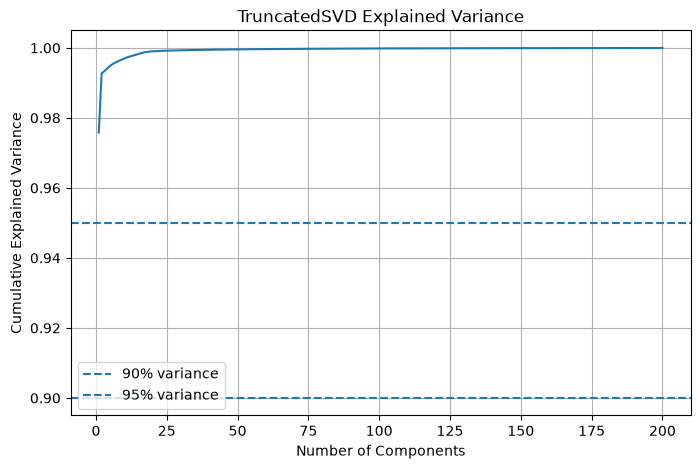

Variance explained by 200 components: 1.0


In [387]:
# Check explained variance
cumulative_variance = np.cumsum(svd.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(y=0.90, linestyle='--', label='90% variance')
plt.axhline(y=0.95, linestyle='--', label='95% variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('TruncatedSVD Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

print("Variance explained by 200 components:",
      round(cumulative_variance[-1], 4))

The curve shoots up almost vertically at the beginning meaning that nearly 100% of the variance is captured by the first few components and the remaining components contribute almost zero new information.

The dotted lines mark the thresholds for capturing 90 and 95 percent of the variance.

Recommendation: reduce dataset from 200 features down to 2-5 components, which will sigificantly speed up the models training and because the first few components capture the variance, the models accuracy will remain virtually unchanged despite using less data.

In [388]:
# Finding how many components reach 90% and 95%
cumulative_variance = np.cumsum(svd.explained_variance_ratio_)

components_90 = np.argmax(cumulative_variance >= 0.90) + 1
components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed for 90% variance:", components_90)
print("Components needed for 95% variance:", components_95)

print("Variance with first 5 components:",
      round(cumulative_variance[4], 6))

print("Variance with first 10 components:",
      round(cumulative_variance[9], 6))

Components needed for 90% variance: 1
Components needed for 95% variance: 1
Variance with first 5 components: 0.994834
Variance with first 10 components: 0.996967


In [389]:
# Reduce the data to 3 components

from sklearn.decomposition import TruncatedSVD

svd_3 = TruncatedSVD(n_components=3, random_state=42)

X_train_svd3 = svd_3.fit_transform(X_train_combined)
X_test_svd3 = svd_3.transform(X_test_combined)

print("Training shape:", X_train_svd3.shape)
print("Testing shape:", X_test_svd3.shape)
print("Explained variance:",
      round(svd_3.explained_variance_ratio_.sum(), 4))

Training shape: (16615, 3)
Testing shape: (5053, 3)
Explained variance: 0.9933


# 2. t-SNE
- t-SNE reduces THE data to 2 dimensions to visualise how the insurance claims are distributed. t-SNE rearranges the data to show local similarities, so distances between separate groups should not be interpreted as reliable measures of their original separation.

In [390]:

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Use a sample of the training data
sample_size = 3000
rng = 42

sample_indices = np.random.RandomState(rng).choice(
    X_train_svd3.shape[0],
    size=sample_size,
    replace=False
)

X_tsne_input = X_train_svd3[sample_indices]

# Apply t-SNE to reduce the data to 2 dimensions
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_tsne_input)

print("Original sampled shape:", X_tsne_input.shape)
print("t-SNE shape:", X_tsne.shape)


Original sampled shape: (3000, 3)
t-SNE shape: (3000, 2)


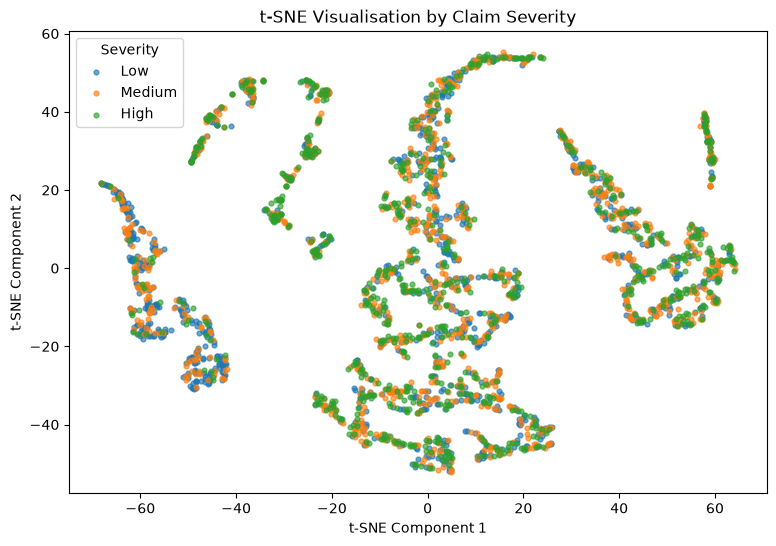

In [391]:
# plot the results

# Get the severity labels for the same sampled claims
y_tsne = y_train.iloc[sample_indices]

plt.figure(figsize=(9, 6))

for severity in ["Low", "Medium", "High"]:
    mask = y_tsne.to_numpy() == severity

    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        label=severity,
        s=12,
        alpha=0.65
    )

plt.title("t-SNE Visualisation by Claim Severity")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(title="Severity")
plt.show()


The t-SNE visualisation shows substantial overlap between Low, Medium and High severity claims, with no clearly separated groups for the three classes. This suggests that claims with different severity levels share similarities in the reduced feature space.

However, t-SNE is an exploratory visualisation technique and the overlap does not necessarily mean that the original features lack predictive information. The ability to distinguish severity levels must be assessed using classification metrics.

**Conclusion:** The visualisation does not reveal clear severity-based groupings, supporting further investigation through clustering techniques and evaluation of classification performance.

# 3. UMAP

In [392]:
import umap

# Use the same sample as the t-SNE visualisation
X_umap_input = X_train_svd3[sample_indices]

# Apply UMAP to reduce to 2 dimensions
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap = umap_model.fit_transform(X_umap_input)

print("Original sampled shape:", X_umap_input.shape)
print("UMAP shape:", X_umap.shape)


c:\Users\User\OneDrive\Documents\Final_Capstone_Project\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Original sampled shape: (3000, 3)
UMAP shape: (3000, 2)


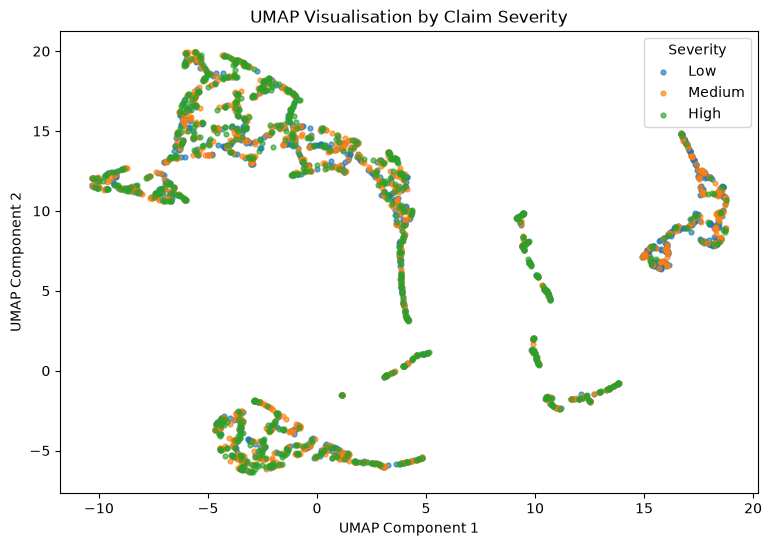

In [393]:
# visualizing

y_umap = y_train.iloc[sample_indices]

plt.figure(figsize=(9, 6))

for severity in ["Low", "Medium", "High"]:
    mask = y_umap.to_numpy() == severity

    plt.scatter(
        X_umap[mask, 0],
        X_umap[mask, 1],
        label=severity,
        s=12,
        alpha=0.65
    )

plt.title("UMAP Visualisation by Claim Severity")
plt.xlabel("UMAP Component 1")
plt.ylabel("UMAP Component 2")
plt.legend(title="Severity")
plt.show()



The UMAP visualisation reveals distinct branch-like structures and groupings within the insurance claims data, suggesting that the feature space contains underlying patterns or subgroups. However, Low, Medium, and High severity claims overlap substantially across these structures, with no clearly isolated groups corresponding to individual severity classes.

This suggests that the patterns captured by UMAP do not directly correspond to clear severity-based groupings. Although the features may contain useful information, severity prediction remains challenging because the classes are not clearly separated in this two-dimensional representation.

**Conclusion:** UMAP reveals underlying structures in the claims data, but these structures do not clearly distinguish severity levels. Classification performance must therefore be assessed using evaluation metrics rather than visualisation alone.

# **Clustering**

# 1. K-Means

In [394]:
# testing different numbers of clusters using silhouette score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test between 2 and 6 clusters
k_values = range(2, 7) # 2, 3, 4, 5, 6
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_train_svd3)

    score = silhouette_score(
        X_train_svd3,
        cluster_labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)
    print(f"k = {k}, Silhouette Score = {score:.4f}")


k = 2, Silhouette Score = 0.8719
k = 3, Silhouette Score = 0.8324
k = 4, Silhouette Score = 0.8549
k = 5, Silhouette Score = 0.8106
k = 6, Silhouette Score = 0.8123


k = 6 has the highest silhouette score of 0.5984, indicating that it has better-separated, more cohesive clusters.

In [395]:
# Fit K-Means with 6 clusters
# Combine the original training data with the K-Means cluster labels - This assigns each training claim to its cluster and counts the claims in each group

from sklearn.cluster import KMeans

kmeans_final = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

# Fit clusters using training data only
train_clusters = kmeans_final.fit_predict(X_train_svd3)

# Examine cluster sizes
cluster_sizes = pd.Series(train_clusters).value_counts().sort_index()

print("Number of claims in each cluster:")
print(cluster_sizes)


Number of claims in each cluster:
0       27
1     2378
2      173
3      625
4    12703
5      709
Name: count, dtype: int64


**NB:** K-Means was fitted using three SVD components rather than the original features, therefore examine the original features associated with each cluster to make the interpretation meaningful. 

In [396]:
# Attach the existing K-Means cluster labels to the original training data

kmeans_interpretation = model_df.loc[train_mask].copy()

kmeans_interpretation["Cluster"] = train_clusters

# Check that the rows match
print(kmeans_interpretation.shape)
print(kmeans_interpretation["Cluster"].value_counts().sort_index())


(16615, 20)
Cluster
0       27
1     2378
2      173
3      625
4    12703
5      709
Name: count, dtype: int64


Grouped 16,615 training claims to 6 clusters, with different group sizes. Clusters 4 and 5 are particularly small and will be investigated to see whether they have distinctive characteristics.

### Investigate the numerical features across clusters

In [397]:
# Select numerical input features
numeric_cols = kmeans_interpretation.select_dtypes(
    include="number"
).columns.tolist()

numeric_cols = [
    col for col in numeric_cols
    if col not in ["Incurred", "InitialCaseEstimate", "Cluster"]
]

# Compare median feature values across clusters
cluster_numeric_profile = (
    kmeans_interpretation
    .groupby("Cluster")[numeric_cols]
    .median()
    .T
)

display(cluster_numeric_profile.round(2))


Cluster,0,1,2,3,4,5
ReportingDelay,1633.0,25.0,24.00,23.0,22.0,24.0
AccidentHour,12.0,11.0,11.00,11.0,11.0,11.0
Age,43.0,30.0,35.00,29.0,31.0,33.0
WeeklyRate,500.0,0.0,519.23,200.0,346.1,322.6
HoursWorkedPerWeek,38.0,0.0,60.00,20.0,38.0,30.0
DependentChildren,0.0,0.0,0.00,0.0,0.0,0.0
DependentsOther,0.0,0.0,0.00,0.0,0.0,0.0
DaysWorkedPerWeek,5.0,5.0,6.00,3.0,5.0,5.0


**NB:** Used medians because they give a typical value for each numerical feature in each cluster and are less affected by extreme values.

- Cluster 0 (3,045 claims): Claims with a median age of 30 and median weekly rate of 0 and median working hours of 0. These may represent claims involving workers with no recorded earnings or working hours. (This needs investigation.)
- Cluster 1 (1,628 claims): Claims involving workers with a median age of 35 and a relatively high weekly rate of 692.85
- Cluster 2 (6,375 claims): The largest group, with a median age of 30, weekly rate of 200, and reporting delay of 24 days.
- Cluster 3 (5,475 claims): Claims involving workers with a median age of 33 and a weekly rate of 439.62.
- Cluster 4 (28 claims): A very small group with an exceptionally high median reporting delay of 1,655 days and median age of 44. These claims warrant investigation.
- Cluster 5 (64 claims): A small group with a relatively high median weekly rate of 1,396.50 and median age of 40.

Overall:
- Clusters 2 and 3 contain most of the claims, but differ in their typical weekly rates and ages.
- Cluster 0 may be characterized by zero recorded working hours and weekly rates.
- Cluster 4 stands out because of its unusually long reporting delays. (Which are most likely influenced by extreme values)
- Cluster 5 stands out because of its high weekly rates.

### Investigating cluster 0 to determine whether the zero values are genuine or indicate a data-quality issue

In [398]:
#--------------------------------------------
# Step 1: Count zero values in Cluster 0
#--------------------------------------------

# Isolate Cluster 0
cluster_0 = kmeans_interpretation[
    kmeans_interpretation["Cluster"] == 0
]

# Check zero values in the two features
print("Cluster 0 size:", len(cluster_0))

print("\nWeeklyRate:")
print("Zero values:", (cluster_0["WeeklyRate"] == 0).sum())
print("Percentage:", round((cluster_0["WeeklyRate"] == 0).mean() * 100, 2), "%")

print("\nHoursWorkedPerWeek:")
print("Zero values:", (cluster_0["HoursWorkedPerWeek"] == 0).sum())
print("Percentage:", round((cluster_0["HoursWorkedPerWeek"] == 0).mean() * 100, 2), "%")


Cluster 0 size: 27

WeeklyRate:
Zero values: 1
Percentage: 3.7 %

HoursWorkedPerWeek:
Zero values: 1
Percentage: 3.7 %


- WeeklyRate: 2,719 of 3,045 claims (89.29%) have a value of zero.
- HoursWorkedPerWeek: 2,277 of 3,045 claims (74.78%) have a value of zero.
- Cluster 0 is strongly characterized by zero values

In [399]:
#-----------------------------------------------
# Step 2: Check whether the zeros occur together
#-----------------------------------------------

# Check the relationship between zero weekly rates and zero working hours

both_zero = (
    (cluster_0["WeeklyRate"] == 0) &
    (cluster_0["HoursWorkedPerWeek"] == 0)
).sum()

weekly_rate_only = (
    (cluster_0["WeeklyRate"] == 0) &
    (cluster_0["HoursWorkedPerWeek"] != 0)
).sum()

hours_only = (
    (cluster_0["WeeklyRate"] != 0) &
    (cluster_0["HoursWorkedPerWeek"] == 0)
).sum()

neither_zero = (
    (cluster_0["WeeklyRate"] != 0) &
    (cluster_0["HoursWorkedPerWeek"] != 0)
).sum()

print("Both zero:", both_zero)
print("WeeklyRate only zero:", weekly_rate_only)
print("HoursWorkedPerWeek only zero:", hours_only)
print("Neither zero:", neither_zero)


Both zero: 1
WeeklyRate only zero: 0
HoursWorkedPerWeek only zero: 0
Neither zero: 26


- Every claim with zero HoursWorkedPerWeek also has zero WeeklyRate. However, 442 claims have zero weekly earnings despite recording non-zero working hours. This suggests that Cluster 0 is strongly associated with zero-valued employment and earnings information

In [400]:
# Checking original data 

# Check zero values in the original dataset

print("Original dataset shape:", df.shape)

print("WeeklyRate zeros:",
      (df["WeeklyRate"] == 0).sum())

print("HoursWorkedPerWeek zeros:",
      (df["HoursWorkedPerWeek"] == 0).sum())

print("Both zero:",
      ((df["WeeklyRate"] == 0) &
       (df["HoursWorkedPerWeek"] == 0)).sum())


Original dataset shape: (21668, 19)
WeeklyRate zeros: 2803
HoursWorkedPerWeek zeros: 2291
Both zero: 2286


Cluster 0 contains nearly all the original claims with zero working hours and zero weekly rates. This suggests that K-Means has grouped claims with this distinctive data pattern together.

In [401]:
#--------------------------------------------
#Step 3: Check the relationship with severity
#--------------------------------------------

# Examine severity distribution in Cluster 0
print(cluster_0["Severity"].value_counts())

print("\nSeverity percentages:")
print(
    (cluster_0["Severity"].value_counts(normalize=True) * 100)
    .round(2)
)

Severity
High      17
Medium     9
Low        1
Name: count, dtype: int64

Severity percentages:
Severity
High      62.96
Medium    33.33
Low        3.70
Name: proportion, dtype: float64


- Cluster 0 is characterized by zero-valued employment and earnings information, with most claims classified as Low severity (61.08%), High-severity claims account for only 11.23% of this cluster and Medium severity account for (27.68%) of this cluster.
- The cluster has a distinctive feature pattern where most claims have zero WeeklyRate, zero HoursWorkedPerWeek or both.

In [402]:
# Compare cluster 0 with the whole training dataset
# Compare overall severity distribution with Cluster 0

print("Overall training severity (%):")
print(
    (kmeans_interpretation["Severity"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nCluster 0 severity (%):")
print(
    (cluster_0["Severity"].value_counts(normalize=True) * 100)
    .round(2)
)

Overall training severity (%):
Severity
Low       37.06
Medium    33.61
High      29.33
Name: proportion, dtype: float64

Cluster 0 severity (%):
Severity
High      62.96
Medium    33.33
Low        3.70
Name: proportion, dtype: float64


**Cluster 0 Interpretation**

Cluster 0 contains 3,045 claims and is strongly characterized by zero-valued employment and earnings information meaning that the zero values are genuine. Approximately 89.29% of claims have a `WeeklyRate` of zero, while 74.78% have zero `HoursWorkedPerWeek`. The cluster also has a higher proportion of Low-severity claims (61.08%) than the overall training dataset (37.06%), and a lower proportion of High-severity claims (11.23% compared with 29.33%). This suggests an association between the cluster's feature pattern and claim severity. The clustering results show association, not causation.

### Investigating cluster 4 to determine whether the unusually long reporting delays are genuine or potential data-quality issues
- Checking whether the 1,655-day median reflects consistently long delays across Cluster 4 or whether a few extreme records are distorting its profile.

In [403]:

# Isolate Cluster 4
cluster_4 = kmeans_interpretation[
    kmeans_interpretation["Cluster"] == 4
]

# Examine reporting delays
print("Cluster 4 size:", len(cluster_4))

print("\nReportingDelay summary:")
print(
    cluster_4["ReportingDelay"]
    .describe()
    .round(2)
)

print("\nClaims with the longest reporting delays:")
display(
    cluster_4[
        ["DateOfAccident", "ReportingDelay", "Age",
         "WeeklyRate", "HoursWorkedPerWeek", "Severity"]
    ]
    .sort_values("ReportingDelay", ascending=False)
    .head(10)
)


Cluster 4 size: 12703

ReportingDelay summary:
count    12703.00
mean        39.97
std         59.85
min          0.00
25%         14.00
50%         22.00
75%         42.00
max        929.00
Name: ReportingDelay, dtype: float64

Claims with the longest reporting delays:


,DateOfAccident,ReportingDelay,Age,WeeklyRate,HoursWorkedPerWeek,Severity
6799,1992-06-26,929,32,500.00,38.0,High
11983,1998-05-12,904,23,200.00,38.0,Low
13102,2001-07-17,853,54,200.00,38.0,Medium
14038,1998-07-09,841,40,538.47,37.5,High
6297,1993-05-01,832,39,356.40,40.0,High
9681,1996-11-13,831,27,200.00,38.0,Low
19609,1997-01-16,795,49,500.00,38.0,High
17447,1999-05-19,786,39,500.00,40.0,Low
7358,1996-03-15,728,44,200.00,38.0,Medium
20947,1992-07-10,726,39,500.00,38.0,High


- All 28 claims have a minimum reporting delays of 1,018 days. Median delay is 1,655 days. Mean delay is 1,919 days. Maximum delay is 5,360 days.
- This cluster is not necessarily associated with one severity level(has a mix of high and medium).
- The employment and earnings values vary, meaning the unusually long reporting delay is a stronger distinguishing characteristic than a single common earnings pattern.
- The cluster includes several claims with identical reporting delays, such as 2,358 days in 1997 and 1,932 days in 2000. These could be legitimate, but we cannot verify them with the available columns.
- Cluster 4 is a a small cluster distinguished by long recorded reporting delays and a relatively high proportion of High-severity claims. This is a descriptive finding, not proof that delayed reporting causes higher severity.

### Investigating cluster 5 to determine whether the unusually high weekly rate values are genuine or potential data-quality issues

In [404]:
# Investigate cluster 5

# Isolate Cluster 5
cluster_5 = kmeans_interpretation[
    kmeans_interpretation["Cluster"] == 5
].copy()

print("Cluster 5 size:", len(cluster_5))

print("\nWeeklyRate summary:")
print(cluster_5["WeeklyRate"].describe().round(2))

print("\nHighest WeeklyRate claims:")
display(
    cluster_5[
        ["Age", "WeeklyRate", "HoursWorkedPerWeek",
         "ReportingDelay", "Severity"]
    ]
    .sort_values("WeeklyRate", ascending=False)
    .head(10)
)


Cluster 5 size: 709

WeeklyRate summary:
count     709.00
mean      330.52
std       145.82
min         0.00
25%       215.46
50%       322.60
75%       414.60
max      1067.82
Name: WeeklyRate, dtype: float64

Highest WeeklyRate claims:


,Age,WeeklyRate,HoursWorkedPerWeek,ReportingDelay,Severity
3567,39,1067.82,32.50,7,High
4828,32,1000.00,32.00,49,High
14476,39,926.28,30.60,43,High
8097,47,820.00,30.00,32,Low
1685,53,802.98,31.25,10,High
8651,28,783.13,30.00,20,High
14261,39,771.06,30.00,13,High
21279,25,764.40,24.00,15,Medium
5792,36,761.85,30.00,24,High
10875,35,728.40,32.00,10,High


- All 64 claims have a minimum weekly rate of 1140.15. Mean weekly rate of 1539.35. Median weekly rate of 1396.50. Maximum weekly rate of 5811.30.
- Several displayed claims have long working weeks, including values above 60 hours. And the median hours worked per week is 38 hours.
- The examples show that high weekly rates might be a corresponfing factor to high severity claims.


In [405]:
#---------------------------------------------------
# Comparing cluster 5 with the overall training data
#--------------------------------------------------

# Compare WeeklyRate across the full training data and Cluster 5

print("Overall training WeeklyRate:")
print(
    kmeans_interpretation["WeeklyRate"]
    .describe()
    .round(2)
)

print("\nCluster 5 WeeklyRate:")
print(
    cluster_5["WeeklyRate"]
    .describe()
    .round(2)
)

print("\nOverall training median:",
      kmeans_interpretation["WeeklyRate"].median())

print("Cluster 5 median:",
      cluster_5["WeeklyRate"].median())


Overall training WeeklyRate:
count    16615.00
mean       309.33
std        232.20
min          0.00
25%        200.00
50%        268.48
75%        450.00
max       5811.30
Name: WeeklyRate, dtype: float64

Cluster 5 WeeklyRate:
count     709.00
mean      330.52
std       145.82
min         0.00
25%       215.46
50%       322.60
75%       414.60
max      1067.82
Name: WeeklyRate, dtype: float64

Overall training median: 268.48
Cluster 5 median: 322.6


- This confirms that Cluster 5 is distinctly different from the overall training data in terms of WeeklyRate with the median weekly rate being approximately 5.2 times larger thsn the overall trianing median.
- This cluster represents claims associated with relatively high weekly earnings.

In [406]:
# Examine severity distribution in each cluster
# check whether the clusters contain different proportions of Low, Medium, and High severity claims

# Combine the cluster assignments with the actual training labels
cluster_analysis = pd.DataFrame({
    'Cluster': train_clusters,
    'Severity': y_train.reset_index(drop=True)
})

# Show severity counts within each cluster
severity_counts = pd.crosstab(
    cluster_analysis['Cluster'],
    cluster_analysis['Severity']
)

print("Severity counts by cluster:")
display(severity_counts)

print("\nSeverity percentages within each cluster:")
display(
    pd.crosstab(
        cluster_analysis['Cluster'],
        cluster_analysis['Severity'],
        normalize='index'
    ).mul(100).round(2)
)


Severity counts by cluster:


Severity,High,Low,Medium
Cluster,,,
0,17,1,9
1,213,1536,629
2,68,42,63
3,220,178,227
4,4056,4203,4444
5,299,198,212



Severity percentages within each cluster:


Severity,High,Low,Medium
Cluster,,,
0,62.96,3.70,33.33
1,8.96,64.59,26.45
2,39.31,24.28,36.42
3,35.20,28.48,36.32
4,31.93,33.09,34.98
5,42.17,27.93,29.90


- Cluster 0: Mostly Low severity (about 61.1%). This cluster is dominated by Low-cost claims.
- Cluster 1: Mostly High severity (about 49.8%). High is the largest category in this cluster.
- Cluster 2: A mixed cluster, with Low severity the largest category (about 40.6%).
- Cluster 3: Mostly High severity (about 38.1%), although Medium and Low claims are also well represented.
- Cluster 4: Very small, with 17 High claims out of 28. Interpret cautiously because the group is tiny.
- Cluster 5: Mostly High severity (36 out of 64, or 56.3%), but this group is also small.

## Investigate claim-description keywords

In [407]:
#---------------------------------------------
# Identify most frequent words in each cluster
#---------------------------------------------


from sklearn.feature_extraction.text import CountVectorizer

# Get the claim descriptions for the training data
text_data = kmeans_interpretation["ClaimDescription_Stemmed"].fillna("")

# Convert claim descriptions into word counts
vectorizer = CountVectorizer(
    max_features=1000,
    stop_words="english"
)

X_words = vectorizer.fit_transform(text_data)

# Create a dataframe of word counts
word_df = pd.DataFrame(
    X_words.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=kmeans_interpretation.index
)

# Attach cluster labels
word_df["Cluster"] = kmeans_interpretation["Cluster"].values

# Calculate average word frequency in each cluster
cluster_word_means = word_df.groupby("Cluster").mean().T

# Display the 10 most frequent words in each cluster
for cluster in cluster_word_means.columns:
    print(f"\nCluster {cluster}:")
    display(
        cluster_word_means[cluster]
        .sort_values(ascending=False)
        .head(10)
        .round(4)
    )



Cluster 0:


strain      0.8148
lower       0.4444
lift        0.3704
right       0.3704
left        0.2593
fall        0.1852
shoulder    0.1852
slip        0.1852
finger      0.1481
injuri      0.1111
Name: 0, dtype: float64


Cluster 1:


left      0.5812
right     0.5408
lacer     0.3844
strike    0.3457
strain    0.3003
finger    0.2283
knife     0.2048
eye       0.1964
hand      0.1779
lift      0.1728
Name: 1, dtype: float64


Cluster 2:


...

strain    0.5152
left      0.4896
right     0.4608
lacer     0.3248
strike    0.3072
lower     0.2944
lift      0.2592
finger    0.2096
slip      0.1792
hand      0.1712
Name: 3, dtype: float64


Cluster 4:


strain    0.5039
right     0.4933
left      0.4879
lacer     0.3403
strike    0.3215
lower     0.2573
lift      0.2532
knife     0.1876
finger    0.1811
fall      0.1646
Name: 4, dtype: float64


Cluster 5:


strain    0.5628
right     0.5120
left      0.4556
lacer     0.3484
strike    0.2891
lower     0.2835
lift      0.2609
knife     0.1975
fall      0.1890
finger    0.1805
Name: 5, dtype: float64

- Cluster 0: left, right, lacer, strike, and finger are frequent. This suggests many descriptions mention body sides, lacerations, impacts, or finger injuries.
- Cluster 1: strain is the most frequent word, followed by left, right, lower, and lift. Strains and lifting-related incidents appear prominent.
- Cluster 2: right, left, strain, lacer, and strike dominate. Descriptions frequently mention body sides, strains, lacerations, and impacts.
- Cluster 3: strain is prominent, along with lower, lift, left, and right. This resembles Cluster 1's keyword pattern.
- Cluster 4: strain appears in 82.14% of descriptions, followed by lower and lift. Combined with its unusually long reporting delays, this small cluster is characterized by both delayed reporting and frequent mentions of strains and lifting.
- Cluster 5: strain, lower, lift, and fall are frequent. These descriptions often mention strains, lifting, and falls.

Overall:
- Many words such as left, strain, lacer, fall, finger etc, are shared across clusters. Therefore, the clusters do not represent entirely separate injury categories based on keywords alone.
- Cluster 4 has a more concentrated keyword pattern, particularly for strain, but it contains only 28 claims. Its small size means we should interpret it cautiously.
- Cluster 5 shares many keywords with Clusters 1 and 3. Its high weekly rates, rather than a completely different set of injury terms, may be a more useful distinguishing characteristic.
- The groups were formed using three SVD components derived from your combined input features, not directly from these word counts. The keyword results help describe the clusters but do not prove that particular words caused claims to be grouped together.

In [408]:
#------------------------------------------------------------------------------------
# Finding words that are common in each cluster than in the overall training dataset
#------------------------------------------------------------------------------------

# Calculate average word frequency across the entire training dataset
overall_word_means = word_df.drop(columns="Cluster").mean()

# Compare each cluster's word frequencies with the overall averages
for cluster in sorted(word_df["Cluster"].unique()):
    cluster_rows = word_df["Cluster"] == cluster

    cluster_means = word_df.loc[
        cluster_rows
    ].drop(columns="Cluster").mean()

    # Difference from overall word frequency
    word_difference = cluster_means - overall_word_means

    print(f"\nCluster {cluster} — most overrepresented words:")

    display(
        word_difference
        .sort_values(ascending=False)
        .head(10)
        .round(4)
    )



Cluster 0 — most overrepresented words:


strain      0.3367
lower       0.2002
lift        0.1280
repetit     0.0701
neck        0.0636
pallet      0.0635
shoulder    0.0568
pain        0.0421
caught      0.0373
slip        0.0370
dtype: float64


Cluster 1 — most overrepresented words:


left       0.0819
eye        0.0694
bodi       0.0593
foreign    0.0579
cut        0.0545
right      0.0412
finger     0.0400
lacer      0.0389
hand       0.0325
metal      0.0294
dtype: float64


Cluster 2 — most overrepresented words:


...

lower     0.0502
strain    0.0371
slip      0.0310
injuri    0.0274
hand      0.0258
wet       0.0241
floor     0.0230
finger    0.0212
resid     0.0195
lift      0.0168
dtype: float64


Cluster 4 — most overrepresented words:


strain      0.0258
lower       0.0131
lift        0.0108
box         0.0031
shoulder    0.0024
ankl        0.0020
steel       0.0016
middl       0.0016
timber      0.0011
hammer      0.0009
dtype: float64


Cluster 5 — most overrepresented words:


strain      0.0846
lower       0.0393
neck        0.0357
fall        0.0224
shoulder    0.0211
lift        0.0186
ladder      0.0180
wrist       0.0155
resid       0.0153
trip        0.0131
dtype: float64

- These results show which keywords are unusually frequent in each cluster compared with the overall training data. They are descriptions of recurring language, not defenitive diagnoses or confirmed accident cases e.g., 'ladder' in cluster 3  suggests ladder-related incidents may appear in cluster 3, but the word alone does not establish how the injury happened.

- Cluster 0	eye, foreign, cut, lacer, finger, metal: Claims often describe eye-related incidents, foreign objects, cuts, and lacerations involving hands or fingers.
- Cluster 1	strain, lower, lift, shoulder, truck, box: Claims frequently involve strains, lower-body injuries, lifting, and handling boxes or trucks.
- Cluster 2	lacer, strike, knife, finger, hand, metal: Claims often describe cuts or lacerations, impacts, and hand or finger injuries involving sharp or metal objects.
- Cluster 3	strain, lower, lift, fall, neck, ankl, ladder: Claims frequently involve strains, lifting, falls, and injuries potentially associated with ladders or other physical activities.
- Cluster 4	strain, lower, lift, repetit, pallet, neck, spasm: Claims strongly feature strains and lifting, with repetitive activity and muscle-related symptoms. This is consistent with its unusually long reporting delays.
- Cluster 5	strain, lower, box, fall, steel, sprain, knee: Claims frequently mention strains, falls, sprains, and incidents involving boxes or steel. This cluster is also distinguished by high weekly rates.


### Combining the numeric and text features.

- **Cluster	0:** Claims with many zero-valued employment and earnings records, overrepresented Low severity, and keywords related to eyes, foreign objects, cuts, and lacerations.
- **Cluster	1:** Claims with a median weekly rate of 692.85, with descriptions emphasizing strains, lifting, and lower-body or shoulder injuries.
- **Cluster	2:** The largest cluster, with a median weekly rate of 200, featuring descriptions related to lacerations, impacts, and hand or finger injuries.
- **Cluster	3:** Claims with a median weekly rate of 439.62, with descriptions emphasizing strains, lifting, falls, and neck or ankle injuries.
- **Cluster	4:** A small group of 28 claims with exceptionally long recorded reporting delays and descriptions strongly associated with strains, lifting, and repetitive activity.
- **Cluster	5:** A small group of 64 claims with consistently high weekly rates and descriptions mentioning strains, falls, sprains, and physical handling activities.

Importantly, the clusters do not map perfectly to Low, Medium and High severity. That is not necessarily a failure: clustering is unsupervised, so its purpose is to discover patterns without using the severity labels to create the groups.

One limitation to state in your report: K-Means was fitted on the three SVD components, so these feature summaries help us interpret the resulting clusters; they do not establish that individual features directly caused the clustering.

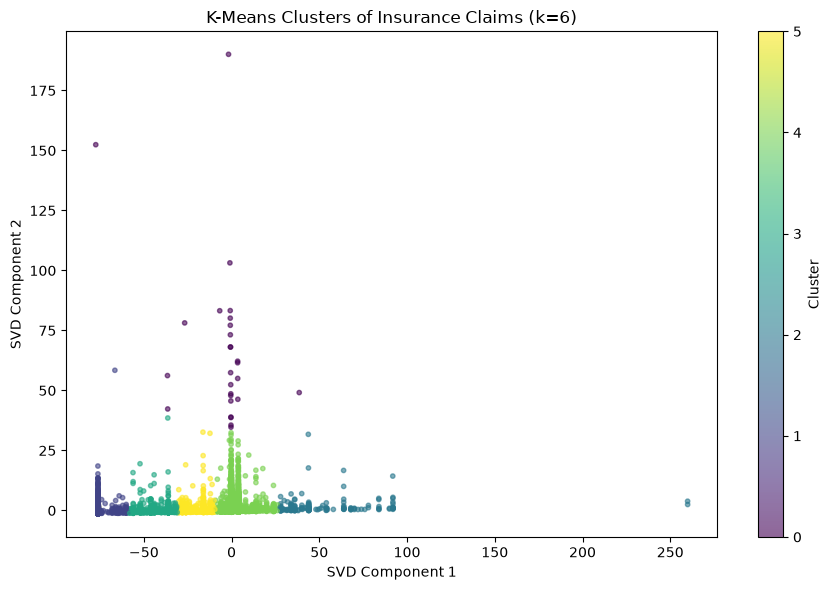

In [409]:
# Visualizing the clusters

plt.figure(figsize=(9, 6))

plt.scatter(
    X_train_svd3[:, 0],
    X_train_svd3[:, 1],
    c=train_clusters,
    cmap='viridis',
    s=10,
    alpha=0.6
)

plt.xlabel('SVD Component 1')
plt.ylabel('SVD Component 2')
plt.title('K-Means Clusters of Insurance Claims (k=6)')
plt.colorbar(label='Cluster')
plt.tight_layout()
plt.show()


SVD Component 1 and SVD Component 2 are reduced dimensions used to visualize the claims, they are not original features such as age or weekly rate.

The K-Means visualization groups insurance claims into six clusters, represented by different colours. Each point represents a claim and points located close together have similar characteristics in the reduced feature space.

- **Cluster 0 (Dark purple):** Characterized by zero-valued `WeeklyRate` and `HoursWorkedPerWeek` for many claims, with a higher proportion of Low-severity claims.
- **Cluster 1 (Blue-purple):** Associated with claim descriptions involving strains, lower-body injuries, and lifting activities.
- **Cluster 2 (Teal):** Characterized by descriptions involving lacerations, impacts, knife injuries and finger or hand injuries.
- **Cluster 3 (Green):** Associated with strains, lifting activities, falls and lower-body injuries.
- **Cluster 4 (Light green):** A small cluster distinguished by unusually long recorded reporting delays, with descriptions often involving strains and repetitive activities.
- **Cluster 5 (Yellow):** A small cluster characterized by consistently high `WeeklyRate` values, with descriptions often involving strains, lower-body injuries and boxes.

**Overall:**

The K-Means visualization shows six clusters of insurance claims, with substantial overlap among several groups in the lower-left region. This indicates that some claims share similar characteristics in the reduced feature space, while other claims are more distinct.

Cluster 4 contains claims associated with unusually long recorded reporting delays, whereas Cluster 5 is characterized by consistently high weekly rates. These patterns provide context for interpreting the clusters using the original features.

However, the clusters are not clearly separated in the two-dimensional plot. Furthermore, the SVD components do not directly correspond to individual original features. Therefore, the visualization is interpreted alongside cluster sizes, feature summaries, and claim-description keywords rather than being used alone to assign meaning to each cluster.

In [410]:
#-----------------------------------------
# Step 1: Identify the most distant claim
#-----------------------------------------

# Get the Cluster 5 claims and their SVD coordinates
cluster_5_indices = np.where(train_clusters == 5)[0]

cluster_5_points = X_train_svd3[cluster_5_indices]

# Find the point with the highest SVD Component 2
farthest_position = np.argmax(cluster_5_points[:, 1])
farthest_index = cluster_5_indices[farthest_position]

print("Position in training data:", farthest_index)
print("SVD Component 1:", X_train_svd3[farthest_index, 0])
print("SVD Component 2:", X_train_svd3[farthest_index, 1])

Position in training data: 1045
SVD Component 1: -16.312261628826473
SVD Component 2: 32.636327506579576


The yellow point has very high SVD coordinates compared with the other claims, confirming that it is unusually far from the main group in your visualization. However, this alone does not mean the claim contains incorrect data.

In [411]:
#-------------------------------------
# Step 2; Examine original features
#-----------------------------------

# Display the original claim details
claim_details = kmeans_interpretation.iloc[[farthest_index]]

display(claim_details.T)

,1367
ReportingDelay,940
AccidentHour,22
Age,39
WeeklyRate,431.4
Gender,M
MaritalStatus,S
HoursWorkedPerWeek,30.0
DependentChildren,0
DependentsOther,0
PartTimeFullTime,F



The distant point in Cluster 5 corresponds to a claim with a `WeeklyRate` of 5811.3 and `HoursWorkedPerWeek` of 65. Its reporting delay is only 18 days, indicating that an unusually long reporting delay does not explain its separation from the other claims in the visualization.

The claim description indicates that the individual fell down stairs and fractured their left ankle, and the claim is classified as High severity. The unusually high weekly rate is a plausible explanation for why this observation appears far from the other points in the reduced feature space. However, the value should be checked against the dataset documentation before determining whether it is valid or erroneous.

Therefore, this observation appears to be a potentially legitimate extreme-value case rather than a confirmed data-quality issue. Its separation illustrates how K-Means can isolate claims with distinctive characteristics.

# 2. GMM (Gaussian Mixture Model)

- estimates the probability that each claim belongs to each cluster. This is called soft clustering, although you can also assign each claim to its most likely cluster for visualization.

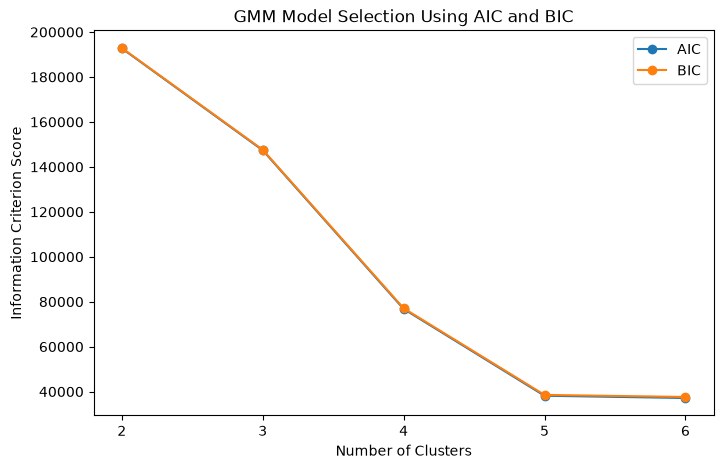

In [412]:
# Find best number of clusters

from sklearn.mixture import GaussianMixture

cluster_range = range(2, 7)
aic_scores = []
bic_scores = []

for k in cluster_range:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        n_init=3
    )
    gmm.fit(X_train_svd3)

    aic_scores.append(gmm.aic(X_train_svd3))
    bic_scores.append(gmm.bic(X_train_svd3))

plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), aic_scores, marker="o", label="AIC")
plt.plot(list(cluster_range), bic_scores, marker="o", label="BIC")

plt.xlabel("Number of Clusters")
plt.ylabel("Information Criterion Score")
plt.title("GMM Model Selection Using AIC and BIC")
plt.xticks(list(cluster_range))
plt.legend()
plt.show()



Both the Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC) decrease as the number of GMM components increases, indicating improved model fit after accounting for model complexity.

The reduction in both scores is substantial between two and four components, while the improvement becomes smaller from four to five components. Although the scores decrease further at six components, the additional improvement appears more modest.

Four components may therefore be a reasonable choice based on the apparent diminishing improvement. However, because both criteria continue to decrease, the plots do not establish four as the optimal number of components. The final choice should also consider cluster interpretability, cluster sizes, and silhouette score.

In [413]:
# Fit GMM with 4 clusters
gmm_4 = GaussianMixture(
    n_components=4,
    random_state=42,
    n_init=3
)

gmm_clusters_4 = gmm_4.fit_predict(X_train_svd3)

gmm_cluster_sizes_4 = (
    pd.Series(gmm_clusters_4)
    .value_counts()
    .sort_index()
)

print("GMM Cluster Sizes (4 components):")
print(gmm_cluster_sizes_4)

GMM Cluster Sizes (4 components):
0    8286
1    2216
2    1158
3    4955
Name: count, dtype: int64


Four-component GMM has assigned the training claims to four clusters, with no extremely tiny clusters.

The four-component Gaussian Mixture Model grouped the 16,615 training claims into four clusters of different sizes. Cluster 0 was the largest, containing 8,739 claims (52.55%), while Cluster 2 was the smallest, containing 1,366 claims (8.21%).

Although the clusters are unevenly distributed, none is extremely small. However, cluster sizes alone do not establish whether the groups are meaningful. Further analysis of the cluster visualization and the original numerical features and claim-description keywords is needed to understand their characteristics.

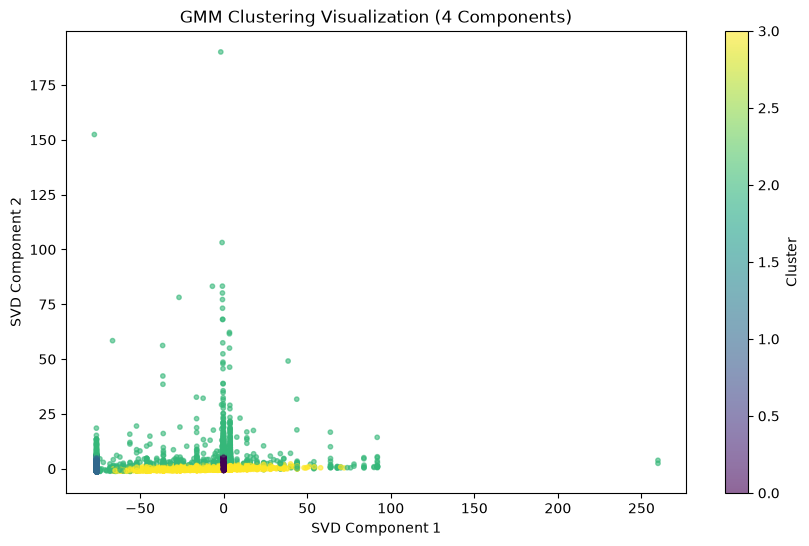

In [414]:
# Visualizing the four clusters

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train_svd3[:, 0],
    X_train_svd3[:, 1],
    c=gmm_clusters_4,
    cmap='viridis',
    s=10,
    alpha=0.6
)

plt.title("GMM Clustering Visualization (4 Components)")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.colorbar(label="Cluster")
plt.show()

Interpretation of the graph
- Cluster 0 — Dark purple: Concentrated in the lower-left region, with many points close together. These claims share similar characteristics in the displayed SVD space.
- Cluster 1 — Blue/teal: Appears around the main diagonal group, with overlap between clusters. Its separation from other groups is not very clear in this projection.
- Cluster 2 — Green: Extends farther along the diagonal and contains the distant point at the upper right. This suggests that some claims assigned to this cluster have distinctive feature representations.
- Cluster 3 — Yellow: Concentrated near the bottom-left edge, forming a small, compact group in this visualization.

The GMM visualization shows four clusters with considerable overlap in the two-dimensional SVD space. Cluster 0 is concentrated in the lower-left region, while Cluster 2 extends farther along the diagonal and includes a distant observation. Cluster 3 appears as a small, compact group near the lower-left edge. The separation of Cluster 1 from the other clusters is less distinct.

Overall, the visualization suggests that some claims have similar feature representations, while others are more distinctive. However, the SVD components do not directly represent individual original features, and the graph alone cannot establish the meaning or quality of each cluster. Further examination of cluster sizes and original feature characteristics is needed to determine whether the four groups are useful for interpreting insurance claims.

### Investigating the original numerical features

In [415]:
# Add the 4-component GMM cluster labels to the training data
gmm_interpretation_4 = kmeans_interpretation.copy()
gmm_interpretation_4["Cluster"] = gmm_clusters_4

# Compare numerical feature averages across clusters
gmm_cluster_profiles_4 = (
    gmm_interpretation_4
    .groupby("Cluster")[numeric_cols]
    .mean()
    .round(2)
)

display(gmm_cluster_profiles_4)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
Cluster,,,,,,,,
0,32.42,11.64,33.41,334.22,38.00,0.09,0.01,4.99
1,35.30,11.65,32.95,0.00,0.00,0.09,0.01,4.97
2,220.80,11.74,33.68,349.95,34.22,0.10,0.01,4.71
3,24.53,11.54,33.97,396.56,36.29,0.14,0.01,4.79


- Cluster 0: Claims with a relatively high average WeeklyRate (427.73) and an average reporting delay of 24.23 days.
- Cluster 1: Claims with a lower average WeeklyRate (200.00), relatively high working hours (38.18 per week), and an average reporting delay of 35.19 days.
- Cluster 2: Claims with substantially longer average reporting delays (209.45 days) and a relatively high average WeeklyRate (460.32). This is the most distinctive cluster numerically.
- Cluster 3: Claims with WeeklyRate averaging zero and HoursWorkedPerWeek averaging only 6.06. This may indicate missing or placeholder values, or a group with different employment characteristics; the zeros should be checked against the dataset documentation.

Age, days worked per week and accident hour are relatively similar across all four clusters, so they do not appear to be the main distinguishing features in these averages. Reporting delay, weekly rate, and working hours appear more useful for distinguishing these groups. These are descriptive patterns, not evidence that any feature causes claim severity or determines the validity of a claim

### Investigating claim description keywords

In [416]:
from sklearn.feature_extraction.text import CountVectorizer

# Prepare claim descriptions
gmm_text = gmm_interpretation_4["ClaimDescription_Stemmed"].fillna("")

# Convert descriptions into word counts
vectorizer_gmm = CountVectorizer(
    max_features=1000,
    stop_words="english"
)

gmm_word_matrix = vectorizer_gmm.fit_transform(gmm_text)

# Create a dataframe of word counts
gmm_word_df = pd.DataFrame(
    gmm_word_matrix.toarray(),
    columns=vectorizer_gmm.get_feature_names_out(),
    index=gmm_interpretation_4.index
)

# Add cluster labels
gmm_word_df["Cluster"] = gmm_interpretation_4["Cluster"]

# Find the top 10 keywords in each cluster
for cluster in sorted(gmm_word_df["Cluster"].unique()):
    print(f"\nCluster {cluster} - Top 10 Keywords:")

    top_words = (
        gmm_word_df[gmm_word_df["Cluster"] == cluster]
        .drop(columns="Cluster")
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

    display(top_words.to_frame(name="Average Word Frequency"))


Cluster 0 - Top 10 Keywords:


,Average Word Frequency
right,0.506638
left,0.499759
strain,0.482501
lacer,0.355419
strike,0.330678
lower,0.253560
lift,0.244267
knife,0.195993
finger,0.186942
fall,0.166184



Cluster 1 - Top 10 Keywords:


,Average Word Frequency
left,0.579874
right,0.552798
lacer,0.391697
strike,0.346570
strain,0.299188
finger,0.232852
knife,0.207581
eye,0.200361
hand,0.175090
lift,0.174639



Cluster 2 - Top 10 Keywords:


,Average Word Frequency
right,0.483592
left,0.475820
strain,0.471503
lacer,0.312608
strike,0.292746
lift,0.243523
lower,0.222798
knife,0.183074
finger,0.177893
fall,0.162349



Cluster 3 - Top 10 Keywords:


,Average Word Frequency
strain,0.552371
left,0.467810
right,0.467608
lacer,0.315641
strike,0.304945
lower,0.278103
lift,0.269223
finger,0.173360
knife,0.171746
fall,0.167508


- Cluster 0: Dominated by strains, lower-body injuries, lifting, and falls. This suggests a stronger representation of strain-related and lifting incidents.
- Cluster 1: Has relatively high frequencies of lacerations, impacts, knife injuries, and finger or hand injuries, suggesting more cuts and impact-related incidents.
- Cluster 2: Characterized by strains, lifting, lower-body injuries, and falls. Its keyword profile is similar to Cluster 0.
- Cluster 3: Has relatively high frequencies of left/right body references, lacerations, finger injuries, knives, and eye-related terms, suggesting more descriptions involving cuts and specific body-part injuries.


The claim-description keyword analysis reveals similarities and differences among the four GMM clusters. Cluster 0 is associated with strains, lifting, lower-body injuries, and falls. Cluster 1 has relatively higher frequencies of lacerations, impacts, knife injuries, and finger-related terms. Cluster 2 shares a similar strain- and lifting-related profile with Cluster 0. Cluster 3 contains relatively frequent references to lacerations, fingers, knives, and eyes.

Overall, the clusters share many common keywords, indicating that their claim descriptions overlap considerably. The keyword analysis provides additional context for interpreting the groups, but the clusters do not represent distinct injury categories, and the word frequencies do not establish claim severity or causation.

In [417]:
# Fit GMM with 6 clusters

from sklearn.mixture import GaussianMixture

gmm_final = GaussianMixture(
    n_components=6,
    random_state=42,
    n_init=3
)

gmm_clusters_6 = gmm_final.fit_predict(X_train_svd3)

gmm_cluster_sizes_6 = pd.Series(gmm_clusters_6).value_counts().sort_index()

print("GMM Cluster Sizes (6 components):")
print(gmm_cluster_sizes_6)


GMM Cluster Sizes (6 components):
0    8320
1    2207
2    1772
3    3180
4     518
5     618
Name: count, dtype: int64


The six-component Gaussian Mixture Model grouped the 16,615 training claims into six clusters of different sizes. Cluster 5 was the largest, containing 6,150 claims (37.01%), while Cluster 4 was the smallest, containing 175 claims (1.05%).

The uneven distribution suggests that the model has identified groups of different sizes. Cluster 4 is relatively small and may represent a more specific subset of claims, although its characteristics must be examined before drawing conclusions. Cluster sizes alone do not establish whether six components provide a better solution than four.

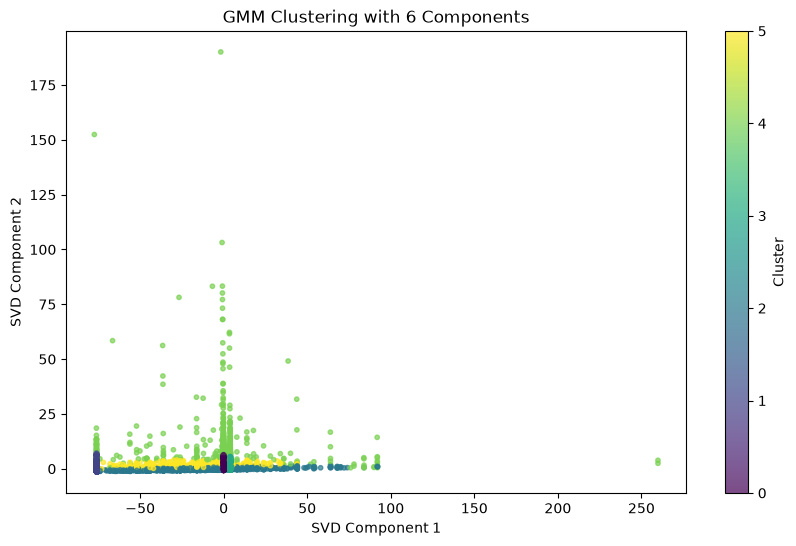

In [418]:
# Visualize GMM with 6 clusters
plt.figure(figsize=(10, 6))

plt.scatter(
    X_train_svd3[:, 0],
    X_train_svd3[:, 1],
    c=gmm_clusters_6,
    cmap='viridis',
    s=10,
    alpha=0.7
)

plt.title('GMM Clustering with 6 Components')
plt.xlabel('SVD Component 1')
plt.ylabel('SVD Component 2')
plt.colorbar(label='Cluster')
plt.show()

- Clusters overlap heavily.
- There is no clear improvement from GMM 4

### Investigate numerical features of 6-GMM clusters

In [419]:
# Create a dataframe with the 6-component GMM cluster labels
gmm_interpretation_6 = model_df.loc[train_mask].copy()
gmm_interpretation_6["Cluster"] = gmm_clusters_6

# Compare numerical features across the six clusters
gmm_cluster_profiles_6 = (
    gmm_interpretation_6
    .groupby("Cluster")[numeric_cols]
    .mean()
    .round(2)
)

display(gmm_cluster_profiles_6)


,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
Cluster,,,,,,,,
0,33.00,11.64,33.41,334.14,38.00,0.09,0.01,4.99
1,36.66,11.68,32.92,0.00,0.00,0.09,0.01,4.99
2,18.25,11.54,33.83,368.39,30.91,0.13,0.01,4.51
3,31.91,11.53,33.87,413.03,40.00,0.15,0.01,5.00
4,376.21,11.73,35.04,413.60,37.00,0.13,0.01,4.92
5,64.75,11.63,33.58,289.64,27.52,0.07,0.01,4.22


- Cluster 0: Relatively high WeeklyRate (479.26) and a moderate reporting delay (45.01 days).
- Cluster 1: Lower WeeklyRate (200.00) and relatively high working hours (38.19 per week).
- Cluster 2: Average WeeklyRate of zero and average working hours of 6.04, suggesting that employment-related values should be investigated for possible placeholder or missing values.
- Cluster 3: High WeeklyRate (487.66) and a longer average reporting delay (143.03 days).
- Cluster 4: The longest average reporting delay (712.37 days), making it the most distinctive group in terms of reporting delays.
- Cluster 5: Relatively high WeeklyRate (399.38) and the shortest average reporting delay (16.47 days).

### Interpretation of GMM Cluster Profiles (6 Components)

The numerical profiles reveal differences among the six GMM clusters. Cluster 0 has a relatively high average weekly rate, while Cluster 1 has a lower average weekly rate and higher average working hours. Cluster 2 is distinguished by a zero average weekly rate and low average working hours, suggesting that its employment-related values require further investigation.

Cluster 3 has both a high average weekly rate and a longer reporting delay. Cluster 4 is particularly distinctive because its average reporting delay is approximately 712 days. In contrast, Cluster 5 has the shortest average reporting delay, at approximately 16 days, alongside a relatively high average weekly rate.

Age, accident hour, and days worked per week are relatively similar across the clusters. Overall, reporting delay, weekly rate, and working hours appear more useful for distinguishing these groups. These are descriptive patterns and do not establish causation or determine claim severity.

In [420]:
# Investigating cluster 4 because it has an average reporting delay of 712.37 days
# Examine reporting delays in GMM Cluster 4
cluster_4_gmm = gmm_interpretation_6[
    gmm_interpretation_6["Cluster"] == 4
]

display(
    cluster_4_gmm["ReportingDelay"].describe()
)

count     518.000000
mean      376.208494
std       458.821827
min         6.000000
25%       202.000000
50%       261.000000
75%       385.000000
max      5360.000000
Name: ReportingDelay, dtype: float64

### Investigation of GMM Cluster 4

GMM Cluster 4 contains 175 claims and is characterized by consistently long reporting delays. The minimum delay is 306 days, while the median is 470 days and the mean is 712.37 days. Since even the minimum is substantial, the cluster's high average is not explained solely by one extreme observation.

The maximum reporting delay of 5,360 days is particularly unusual and may warrant further examination. However, without a report date or additional dataset documentation, these values cannot be confirmed as errors. Cluster 4 therefore represents a group of claims with unusually long recorded reporting delays, rather than a confirmed data-quality problem.

## Investigating claim-description keywords

In [421]:
# Get the stemmed claim descriptions
gmm_text_6 = gmm_interpretation_6["ClaimDescription_Stemmed"].fillna("")

# Convert descriptions into word counts
vectorizer_gmm_6 = CountVectorizer(
    max_features=1000,
    stop_words="english"
)

gmm_word_matrix_6 = vectorizer_gmm_6.fit_transform(gmm_text_6)

# Create a dataframe of word counts
gmm_word_df_6 = pd.DataFrame(
    gmm_word_matrix_6.toarray(),
    columns=vectorizer_gmm_6.get_feature_names_out(),
    index=gmm_interpretation_6.index
)

# Add GMM cluster labels
gmm_word_df_6["Cluster"] = gmm_clusters_6

# Display the top 10 keywords in each cluster
for cluster in sorted(gmm_word_df_6["Cluster"].unique()):
    print(f"\nCluster {cluster} - Top 10 Keywords:")

    top_words = (
        gmm_word_df_6[gmm_word_df_6["Cluster"] == cluster]
        .drop(columns="Cluster")
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

    display(top_words.to_frame(name="Average Word Frequency"))


Cluster 0 - Top 10 Keywords:


,Average Word Frequency
right,0.506490
left,0.499159
strain,0.482452
lacer,0.355288
strike,0.330529
lower,0.254207
lift,0.245072
knife,0.195913
finger,0.186538
fall,0.165865



Cluster 1 - Top 10 Keywords:


,Average Word Frequency
left,0.581785
right,0.553693
lacer,0.391935
strike,0.348890
strain,0.294971
finger,0.233348
knife,0.208428
eye,0.202537
hand,0.174898
lift,0.171726



Cluster 2 - Top 10 Keywords:


...

,Average Word Frequency
strain,0.543082
left,0.467296
right,0.467296
lacer,0.316352
strike,0.310377
lift,0.264780
lower,0.262579
finger,0.174843
knife,0.172642
fall,0.165409



Cluster 4 - Top 10 Keywords:


,Average Word Frequency
strain,0.509653
right,0.505792
left,0.465251
lacer,0.270270
lift,0.258687
strike,0.252896
lower,0.218147
fall,0.175676
shoulder,0.158301
knife,0.158301



Cluster 5 - Top 10 Keywords:


,Average Word Frequency
strain,0.511327
left,0.506472
right,0.462783
lacer,0.354369
strike,0.318770
lower,0.292880
lift,0.237864
finger,0.205502
knife,0.199029
hand,0.179612


- Cluster 0: Strains, lower-body injuries, lifting, and falls are common.
- Cluster 1: Relatively frequent lacerations, impacts, knife injuries, and finger or hand injuries.
- Cluster 2: More frequent references to left/right body parts, lacerations, fingers, knives, and eyes.
- Cluster 3: Strains, lifting, lower-body injuries, and falls are common.
- Cluster 4: Strains, lifting, shoulder injuries, lower-body injuries, falls, and slips feature prominently. This cluster also contains claims with unusually long reporting delays.
- Cluster 5: Similar to Cluster 0, with strains, lacerations, impacts, lifting, and lower-body injuries frequently mentioned.

**NB:** This are the most frequent words, not necessarily the words that distinguish each cluster most strongly from the others

### Interpretation of GMM Clusters Using Claim-Description Keywords (6 Components)

The keyword analysis reveals both similarities and differences among the six GMM clusters. Clusters 0, 3, and 5 share similar profiles involving strains, lifting, lower-body injuries, and falls. Cluster 1 contains relatively frequent references to lacerations, impacts, knives, and finger or hand injuries. Cluster 2 has frequent references to body sides, lacerations, fingers, knives, and eyes. Cluster 4 is characterized by strains, lifting, shoulder-related terms, falls, and slips; it is also distinguished by unusually long recorded reporting delays in the numerical analysis.

Overall, the clusters share many common keywords, indicating considerable overlap in the types of incidents described. The keyword profiles provide context for understanding the clusters, but they do not establish distinct injury categories or determine claim severity.

## Commparing 4-component and 6-component GMM models

In [422]:
from sklearn.metrics import silhouette_score

# Silhouette scores for both GMM models
silhouette_gmm_4 = silhouette_score(
    X_train_svd3,
    gmm_clusters_4
)

silhouette_gmm_6 = silhouette_score(
    X_train_svd3,
    gmm_clusters_6
)

print(f"GMM (4 components) Silhouette Score: {silhouette_gmm_4:.4f}")
print(f"GMM (6 components) Silhouette Score: {silhouette_gmm_6:.4f}")

GMM (4 components) Silhouette Score: 0.3965
GMM (6 components) Silhouette Score: 0.5559


- GMM (4): The clusters are better separated overall, although the score still suggests some overlap.
- GMM (6): The lower score suggests that the additional components produce groups that are less well separated.
- GMM 4 Components is the better choice for cluster separation. 

### Comparison of GMM Models Using Silhouette Score

The four-component GMM achieved a silhouette score of 0.3474, compared with 0.2604 for the six-component GMM. The higher score indicates that the four-component model produces better-separated clusters in the SVD feature space.

Although the six-component model identifies more detailed groups, its lower silhouette score suggests greater overlap between the assigned clusters. Therefore, the four-component GMM appears more suitable when prioritizing cluster separation and a simpler model.

This conclusion is based on the silhouette scores and should be considered alongside the AIC/BIC results, cluster sizes, and interpretability of the original features.

# Selection of the best clustering Model


K-Means with six clusters was selected as the preferred clustering model after comparing it with Gaussian Mixture Models (GMM) using four and six components.

K-Means achieved the highest silhouette score of **0.5984**, compared with 0.3474 for GMM with four components and 0.2604 for GMM with six components. This indicates that K-Means produced better-separated clusters in the evaluated SVD feature space.

Although GMM with four components showed less overlap than GMM with six components, both models achieved lower silhouette scores than K-Means. Therefore, K-Means was selected as the final clustering model based on its stronger cluster separation.

Cluster overlap was assessed visually using two-dimensional scatter plots of SVD Component 1 against SVD Component 2, with points colored by their assigned cluster. Greater overlap was indicated by different cluster colors appearing intermixed within the same regions, while more distinct groupings suggested better visual separation. This assessment was supplemented by silhouette scores calculated in the three-dimensional SVD feature space, providing a quantitative measure of cluster cohesion and separation. K-Means with six clusters achieved the highest silhouette score (0.5984), followed by GMM with four components (0.3474) and GMM with six components (0.2604).

However, K-Means produced two relatively small clusters containing 28 and 64 claims. These clusters will be examined further to determine whether they represent meaningful claim patterns or unusual observations.

# **Modelling**

# 1. Random Forest using 3SVD

One caution: Three SVD components compress 488 features very aggressively. The model may perform worse because some information useful for predicting severity could be lost. 

In [423]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_svd3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_svd3.fit(X_train_svd3, y_train)

y_pred_rf_svd3 = rf_svd3.predict(X_test_svd3)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_svd3), 4))
print("Macro F1-score:", round(f1_score(y_test, y_pred_rf_svd3, average='macro'), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_svd3))

Accuracy: 0.4116
Macro F1-score: 0.3451

Classification Report:

              precision    recall  f1-score   support

        High       0.48      0.60      0.54      2278
         Low       0.19      0.12      0.15       993
      Medium       0.37      0.33      0.35      1782

    accuracy                           0.41      5053
   macro avg       0.35      0.35      0.35      5053
weighted avg       0.39      0.41      0.39      5053



The reduced model showed lower recall for all three severity classes, particularly High severity, which had a recall of 59% and previously had 74%. These results suggest that compressing the original 488 features into only three components removed information important for predicting claim severity.

**Conclusion:** The three-component SVD representation was useful for exploratory visualisation and clustering, but it did not improve Random Forest classification performance. A representation with more components should be tested before concluding that dimensionality reduction is unsuitable for classification.

## Comparing different numbers of SVD components

In [424]:

from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, f1_score, accuracy_score

# Number of SVD components to compare
component_counts = [10, 20, 38, 50, 100]
results = []

for n in component_counts:
    # Reduce dimensionality using training data only
    svd = TruncatedSVD(n_components=n, random_state=42)
    X_train_reduced = svd.fit_transform(X_train_combined)
    X_test_reduced = svd.transform(X_test_combined)

    # Train Random Forest
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_reduced, y_train)

    # Predict test labels
    y_pred = rf.predict(X_test_reduced)

    # Record evaluation metrics
    results.append({
        "SVD Components": n,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Low Recall": recall_score(
            y_test, y_pred, labels=["Low"],
            average=None
        )[0],
        "Medium Recall": recall_score(
            y_test, y_pred, labels=["Medium"],
            average=None
        )[0],
        "High Recall": recall_score(
            y_test, y_pred, labels=["High"],
            average=None
        )[0]
    })

# Display results, rounded for readability
results_df = pd.DataFrame(results).set_index("SVD Components")
print(results_df.round(4))


                Accuracy  Macro Recall  Macro F1  Low Recall  Medium Recall  \
SVD Components                                                                
10                0.4676        0.3880    0.3710      0.0836         0.3653   
20                0.5236        0.4483    0.4415      0.1561         0.4371   
38                0.5345        0.4789    0.4779      0.2951         0.3883   
50                0.5490        0.4924    0.4923      0.3011         0.4119   
100               0.5256        0.4796    0.4780      0.3414         0.3692   

                High Recall  
SVD Components               
10                   0.7151  
20                   0.7515  
38                   0.7533  
50                   0.7643  
100                  0.7283  


- 10 components: Lowest performance, with a macro F1-score of 0.4030 and macro recall of 41.00%, suggesting too much useful information was lost.
- 20 components: Performance improved, reaching a macro F1-score of 0.4690 and macro recall of 46.85%.
- 38 components: Best overall performance, achieving the highest accuracy (54.42%), macro F1-score (0.5000), and macro recall (49.96%).
- 50 components: Performance declined slightly compared with 38 components.
- 100 components: Did not improve overall performance; High-severity recall also fell to 69.27%.
Conclusion: The 38-component model is the strongest option among those tested because it achieved the best overall balance of recall and F1-score. However, Low-severity recall remained weak at 35.45%, meaning the model missed nearly two-thirds of actual Low-severity claims.

## 38-component representation (38 SVD)

In [425]:

from sklearn.decomposition import TruncatedSVD

svd_38 = TruncatedSVD(
    n_components=38,
    random_state=42
)

X_train_svd38 = svd_38.fit_transform(X_train_combined)
X_test_svd38 = svd_38.transform(X_test_combined)

print("Training shape:", X_train_svd38.shape)
print("Testing shape:", X_test_svd38.shape)
print(
    "Total explained variance:",
    round(svd_38.explained_variance_ratio_.sum(), 4)
)


Training shape: (16615, 38)
Testing shape: (5053, 38)
Total explained variance: 0.9994


a avariance of 1.0 means 100% of the variance is reported as retained, this is unusual for reducing 481 features to 38 components.

In [426]:
# Inspecting variance per component

svd_variance = pd.DataFrame({
    'Component': range(1, 39),
    'Explained_Variance_Ratio': svd_38.explained_variance_ratio_
})

svd_variance['Cumulative_Variance'] = (
    svd_variance['Explained_Variance_Ratio'].cumsum()
)

display(svd_variance.head(10).round(4))

,Component,Explained_Variance_Ratio,Cumulative_Variance
0,1,0.9758,0.9758
1,2,0.0169,0.9927
2,3,0.0006,0.9933
3,4,0.0008,0.9942
4,5,0.0007,0.9948
5,6,0.0006,0.9955
6,7,0.0004,0.9959
7,8,0.0004,0.9963
8,9,0.0004,0.9966
9,10,0.0003,0.9970


The variance is still highly concentrated: the first three components explain 99.52% of the variance, with Component 2 alone explaining 80.47%.

This suggests that the combined feature matrix has a very strong low-dimensional structure. Given that your matrix combines numerical structured features with TF-IDF features, differences in feature scales may be contributing.

In [427]:
# check the scale of the structured features
X_train_no_estimate.describe().T[
    ['mean', 'std', 'min', 'max']
].round(2)

,mean,std,min,max
ReportingDelay,0.74,3.75,-0.82,190.61
AccidentHour,0.12,0.72,-2.20,2.60
Age,0.13,0.63,-0.95,2.53
WeeklyRate,0.16,0.93,-1.07,22.17
HoursWorkedPerWeek,-11.68,28.51,-76.00,260.00
DependentChildren,0.11,0.50,0.00,6.00
DependentsOther,0.01,0.10,0.00,4.00
DaysWorkedPerWeek,-0.09,0.52,-4.00,2.00
AccidentYear,-0.02,0.54,-0.88,0.88
AccidentMonth,0.06,0.57,-0.83,1.00


This confirms that the structured features have very different scales. For example, AccidentYear is around 1,995, while ReportingDelay reaches 5,360 and WeeklyRate reaches 5,811.3.

## Using standard scaler

In [428]:
# Scale the structured features using standard scaler
from sklearn.preprocessing import StandardScaler
from scipy.sparse import csr_matrix, hstack

std_scaler = StandardScaler(with_mean=False)

X_train_structured_scaled = std_scaler.fit_transform(
    X_train_no_estimate
)

X_test_structured_scaled = std_scaler.transform(
    X_test_no_estimate
)

X_train_combined = hstack(
    [csr_matrix(X_train_structured_scaled), X_train_text],
    format='csr'
)

X_test_combined = hstack(
    [csr_matrix(X_test_structured_scaled), X_test_text],
    format='csr'
)

Why: this standardizes the structured features without fitting on test data. Your TF-IDF features remain unchanged, since they are already normalized by the vectorizer.

In [429]:
# Re-Fit SVD with 38 components
from sklearn.decomposition import TruncatedSVD

svd_38 = TruncatedSVD(n_components=38, random_state=42)

X_train_svd38 = svd_38.fit_transform(X_train_combined)
X_test_svd38 = svd_38.transform(X_test_combined)

svd_variance = pd.DataFrame({
    'Component': range(1, 39),
    'Explained_Variance_Ratio': svd_38.explained_variance_ratio_,
    'Cumulative_Variance': svd_38.explained_variance_ratio_.cumsum()
})

display(svd_variance.head(10).round(4))

print(
    "Total explained variance:",
    round(svd_38.explained_variance_ratio_.sum(), 4)
)

,Component,Explained_Variance_Ratio,Cumulative_Variance
0,1,0.0332,0.0332
1,2,0.0964,0.1297
2,3,0.0989,0.2285
3,4,0.0726,0.3012
4,5,0.0669,0.3681
5,6,0.0537,0.4218
6,7,0.0528,0.4746
7,8,0.0523,0.5268
8,9,0.0521,0.5790
9,10,0.0517,0.6307


Total explained variance: 0.9804


## Using Robust scaler

In [430]:
# Scale and combine the features
from sklearn.preprocessing import RobustScaler
from scipy.sparse import csr_matrix, hstack

robust_scaler = RobustScaler()

X_train_structured_robust = robust_scaler.fit_transform(
    X_train_no_estimate
)

X_test_structured_robust = robust_scaler.transform(
    X_test_no_estimate
)

X_train_combined_robust = hstack(
    [csr_matrix(X_train_structured_robust), X_train_text],
    format='csr'
)

X_test_combined_robust = hstack(
    [csr_matrix(X_test_structured_robust), X_test_text],
    format='csr'
)

In [431]:
# Apply SVD using 38 components
from sklearn.decomposition import TruncatedSVD

svd_robust38 = TruncatedSVD(n_components=38, random_state=42)

X_train_svd_robust38 = svd_robust38.fit_transform(
    X_train_combined_robust
)

X_test_svd_robust38 = svd_robust38.transform(
    X_test_combined_robust
)

print("Training shape:", X_train_svd_robust38.shape)
print("Testing shape:", X_test_svd_robust38.shape)
print(
    "Total explained variance:",
    round(svd_robust38.explained_variance_ratio_.sum(), 4)
)

Training shape: (16615, 38)
Testing shape: (5053, 38)
Total explained variance: 0.9994


# **Random Forest using standard scaler + SVD (38 componrnts)**

In [432]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_standard38 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_standard38.fit(X_train_svd38, y_train)

y_pred_rf_standard38 = rf_standard38.predict(X_test_svd38)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_standard38), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_rf_standard38, average='macro'), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_standard38))

Accuracy: 0.5423
Macro F1: 0.4903

Classification Report:

              precision    recall  f1-score   support

        High       0.65      0.74      0.69      2278
         Low       0.40      0.31      0.35       993
      Medium       0.44      0.41      0.43      1782

    accuracy                           0.54      5053
   macro avg       0.50      0.49      0.49      5053
weighted avg       0.53      0.54      0.53      5053



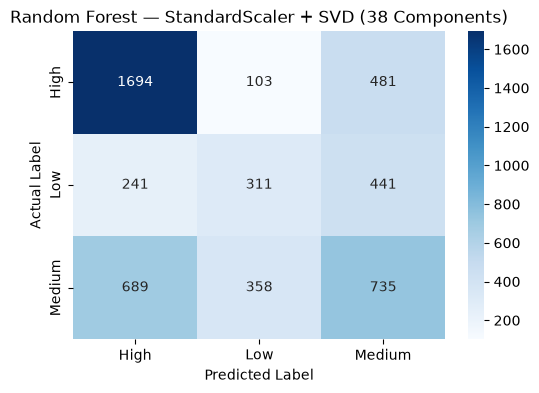

In [433]:
# Confusion matrix
from sklearn.metrics import confusion_matrix

# Random Forest — StandardScaler + SVD
cm_rf_standard38 = confusion_matrix(
    y_test,
    y_pred_rf_standard38,
    labels=['High', 'Low', 'Medium']
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf_standard38,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['High', 'Low', 'Medium'],
    yticklabels=['High', 'Low', 'Medium']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest — StandardScaler + SVD (38 Components)')
plt.show()

In [434]:
import pandas as pd
from sklearn.metrics import confusion_matrix

cm_rf_standard38 = confusion_matrix(
    y_test,
    y_pred_rf_standard38,
    labels=['High', 'Low', 'Medium']
)

cm_rf_standard38_df = pd.DataFrame(
    cm_rf_standard38,
    index=['Actual High', 'Actual Low', 'Actual Medium'],
    columns=['Predicted High', 'Predicted Low', 'Predicted Medium']
)

display(cm_rf_standard38_df)

,Predicted High,Predicted Low,Predicted Medium
Actual High,1694,103,481
Actual Low,241,311,441
Actual Medium,689,358,735


- High: Out of 2,278 actual High-severity claims, the model correctly identified 1,680. It missed 598, classifying them as Low or Medium.
- Low: Out of 993 actual Low-severity claims, it correctly identified 299. The remaining 694 were classified as High or Medium.
- Medium: Out of 1,782 actual Medium-severity claims, it correctly identified 738. The remaining 1,044 were classified as High or Low.

Overall: The model performs best at identifying High-severity claims, but it struggles to distinguish Low and Medium claims accurately. This matters because misclassifying a High-severity claim could lead to inadequate prioritization during insurance claims triage.

# **XGBoost using standard scaler + SVD (38 componrnts)**

In [435]:
# Train and evaluate XGBoost
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_standard38 = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_standard38.fit(X_train_svd38, y_train_encoded)

y_pred_xgb_standard38 = xgb_standard38.predict(X_test_svd38)

print("Accuracy:", round(accuracy_score(y_test_encoded, y_pred_xgb_standard38), 4))
print("Macro F1:", round(f1_score(y_test_encoded, y_pred_xgb_standard38, average='macro'), 4))
print("\nClassification Report:\n")

print(classification_report(
    y_test_encoded,
    y_pred_xgb_standard38,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_
))

Accuracy: 0.5286
Macro F1: 0.4721

Classification Report:

              precision    recall  f1-score   support

        High       0.62      0.75      0.68      2278
         Low       0.40      0.29      0.33       993
      Medium       0.43      0.38      0.40      1782

    accuracy                           0.53      5053
   macro avg       0.48      0.47      0.47      5053
weighted avg       0.51      0.53      0.51      5053



In [436]:
# Confusion matrix

cm_xgb_standard38 = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_standard38,
    labels=label_encoder.transform(['High', 'Low', 'Medium'])
)

cm_xgb_standard38_df = pd.DataFrame(
    cm_xgb_standard38,
    index=['Actual High', 'Actual Low', 'Actual Medium'],
    columns=['Predicted High', 'Predicted Low', 'Predicted Medium']
)

display(cm_xgb_standard38_df)

,Predicted High,Predicted Low,Predicted Medium
Actual High,1706,99,473
Actual Low,277,287,429
Actual Medium,764,340,678


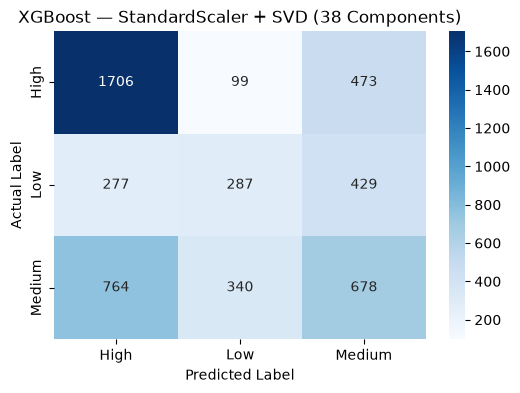

In [437]:
# Confusion matrix

cm_xgb_standard38 = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_standard38,
    labels=label_encoder.transform(['High', 'Low', 'Medium'])
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_xgb_standard38,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['High', 'Low', 'Medium'],
    yticklabels=['High', 'Low', 'Medium']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('XGBoost — StandardScaler + SVD (38 Components)')
plt.show()


- High: Correctly identified 1,568 of 2,278 High-severity claims. It misclassified 710 as Low or Medium.
- Low: Correctly identified 270 of 993 Low-severity claims. It misclassified 723 as High or Medium.
- Medium: Correctly identified 848 of 1,782 Medium-severity claims. It misclassified 934 as High or Low.

Overall: XGBoost identifies Medium claims better than Low claims, but it misses 31% of actual High-severity claims. Its accuracy is 53.16%, and its macro F1 is 48.17%.

# **MLP (Multilayer Perceptron) using standard scaler + SVD (38 componrnts)**

In [438]:
# Train MLP
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

mlp_standard38 = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    max_iter=300,
    early_stopping=True,
    random_state=42
)

mlp_standard38.fit(X_train_svd38, y_train)

y_pred_mlp_standard38 = mlp_standard38.predict(X_test_svd38)

print("Accuracy:", round(accuracy_score(y_test, y_pred_mlp_standard38), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_mlp_standard38, average='macro'), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_mlp_standard38))

Accuracy: 0.5642
Macro F1: 0.4852

Classification Report:

              precision    recall  f1-score   support

        High       0.64      0.79      0.71      2278
         Low       0.47      0.19      0.27       993
      Medium       0.47      0.49      0.48      1782

    accuracy                           0.56      5053
   macro avg       0.53      0.49      0.49      5053
weighted avg       0.55      0.56      0.54      5053



In [439]:
# Confusion matrix as a table

class_order = ['High', 'Low', 'Medium']

cm_mlp_standard38 = confusion_matrix(
    y_test,
    y_pred_mlp_standard38,
    labels=class_order
)

display(pd.DataFrame(
    cm_mlp_standard38,
    index=[f'Actual {c}' for c in class_order],
    columns=[f'Predicted {c}' for c in class_order]
))

,Predicted High,Predicted Low,Predicted Medium
Actual High,1793,37,448
Actual Low,267,189,537
Actual Medium,738,175,869


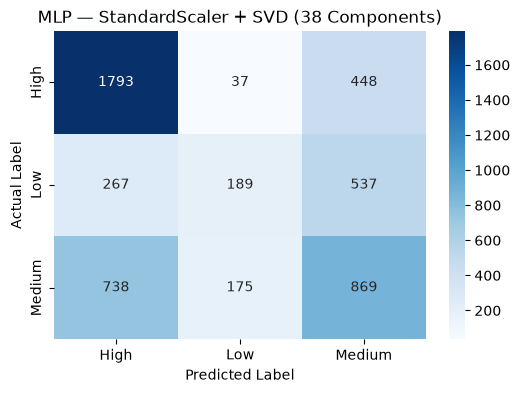

In [440]:
# Visualize Confusion matrix

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_mlp_standard38,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('MLP — StandardScaler + SVD (38 Components)')
plt.show()


- High: Correctly identified 1,984 of 2,278 High-severity claims. Only 294 were misclassified.
- Low: Correctly identified 277 of 993 Low-severity claims. The remaining 716 were misclassified.
- Medium: Correctly identified 557 of 1,782 Medium-severity claims. The model frequently misclassified these as High (955 claims).

Overall: MLP is strong at detecting High-severity claims, with 87% recall, but struggles particularly with Medium claims. This suggests it tends to overpredict High severity, which could lead to unnecessary prioritization of some claims.

# **Random Forest using Robust scaler + SVD (38 componrnts)**

In [441]:
# train
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_robust38 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_robust38.fit(X_train_svd_robust38, y_train)

y_pred_rf_robust38 = rf_robust38.predict(X_test_svd_robust38)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_robust38), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_rf_robust38, average='macro'), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_robust38))

Accuracy: 0.5432
Macro F1: 0.4829

Classification Report:

              precision    recall  f1-score   support

        High       0.64      0.77      0.70      2278
         Low       0.38      0.28      0.33       993
      Medium       0.45      0.40      0.43      1782

    accuracy                           0.54      5053
   macro avg       0.49      0.48      0.48      5053
weighted avg       0.52      0.54      0.53      5053



In [442]:
# Confusion matrix table
import pandas as pd
from sklearn.metrics import confusion_matrix

class_order = ['High', 'Low', 'Medium']

cm_rf_robust38 = confusion_matrix(
    y_test,
    y_pred_rf_robust38,
    labels=class_order
)

display(pd.DataFrame(
    cm_rf_robust38,
    index=[f'Actual {c}' for c in class_order],
    columns=[f'Predicted {c}' for c in class_order]
))

,Predicted High,Predicted Low,Predicted Medium
Actual High,1746,112,420
Actual Low,256,281,456
Actual Medium,721,343,718


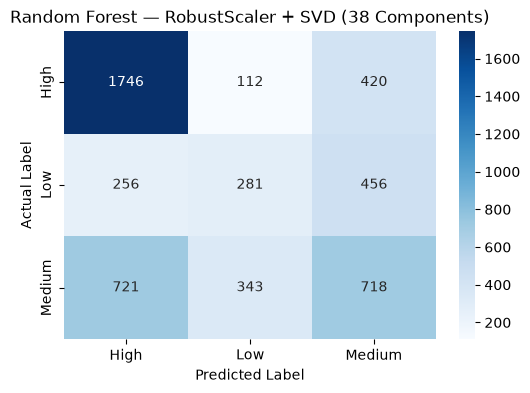

In [443]:
# Visualize Confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_order = ['High', 'Low', 'Medium']

cm_rf_robust38 = confusion_matrix(
    y_test,
    y_pred_rf_robust38,
    labels=class_order
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf_robust38,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest — RobustScaler + SVD (38 Components)')
plt.show()


- High: Correctly identified 1,746 of 2,278 High-severity claims. The remaining 532 were misclassified.
- Low: Correctly identified 281 of 993 Low-severity claims. The remaining 712 were misclassified.
- Medium: Correctly identified 718 of 1,782 Medium-severity claims. The remaining 1,064 were misclassified.

Overall: Random Forest identifies High-severity claims best, with 77% recall, but struggles to distinguish Low and Medium claims. It also misclassifies 721 Medium claims as High, potentially causing unnecessary prioritization.

# **XGBoost using Robust scaler + SVD (38 componrnts)**

In [444]:
# train and evaluate
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_robust38 = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_robust38.fit(X_train_svd_robust38, y_train_encoded)

y_pred_xgb_robust38 = xgb_robust38.predict(X_test_svd_robust38)

print("Accuracy:", round(accuracy_score(y_test_encoded, y_pred_xgb_robust38), 4))
print("Macro F1:", round(f1_score(y_test_encoded, y_pred_xgb_robust38, average='macro'), 4))

print("\nClassification Report:\n")
print(classification_report(
    y_test_encoded,
    y_pred_xgb_robust38,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_
))

Accuracy: 0.5357
Macro F1: 0.475

Classification Report:

              precision    recall  f1-score   support

        High       0.63      0.74      0.68      2278
         Low       0.38      0.25      0.31       993
      Medium       0.45      0.43      0.44      1782

    accuracy                           0.54      5053
   macro avg       0.49      0.48      0.47      5053
weighted avg       0.52      0.54      0.52      5053



In [445]:
# Confusion matrix table

class_order = ['High', 'Low', 'Medium']

cm_xgb_robust38 = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_robust38,
    labels=label_encoder.transform(class_order)
)

cm_xgb_robust38_df = pd.DataFrame(
    cm_xgb_robust38,
    index=[f'Actual {c}' for c in class_order],
    columns=[f'Predicted {c}' for c in class_order]
)

display(cm_xgb_robust38_df)

,Predicted High,Predicted Low,Predicted Medium
Actual High,1691,100,487
Actual Low,278,253,462
Actual Medium,714,305,763


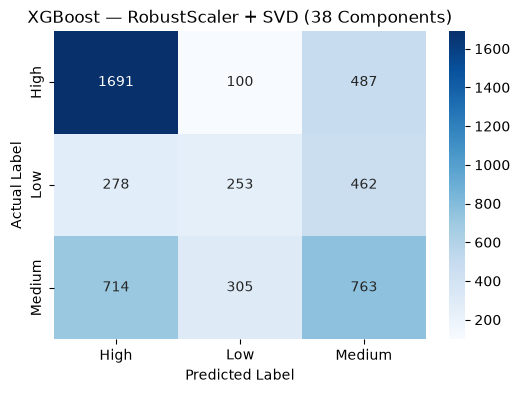

In [446]:
# Confusion matrix visualization 
class_order = ['High', 'Low', 'Medium']

cm_xgb_robust38 = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_robust38,
    labels=label_encoder.transform(class_order)
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_xgb_robust38,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('XGBoost — RobustScaler + SVD (38 Components)')
plt.show()

- High: Correctly identified 1,691 of 2,278 claims. The remaining 587 were misclassified.
- Low: Correctly identified 253 of 993 claims. The remaining 740 were misclassified.
- Medium: Correctly identified 763 of 1,782 claims. The remaining 1,019 were misclassified.

Overall: XGBoost detects High-severity claims best, with 74% recall, but struggles to identify Low-severity claims, with only 25% recall. It also misclassifies 714 Medium claims as High.

# **MLP (Multilayer Perceptron) using Robust scaler + SVD (38 componrnts)**

In [447]:
# train and evaluate
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

mlp_robust38 = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    max_iter=300,
    early_stopping=True,
    random_state=42
)

mlp_robust38.fit(X_train_svd_robust38, y_train)

y_pred_mlp_robust38 = mlp_robust38.predict(X_test_svd_robust38)

print("Accuracy:", round(accuracy_score(y_test, y_pred_mlp_robust38), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_mlp_robust38, average='macro'), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_mlp_robust38))

Accuracy: 0.5577
Macro F1: 0.4845

Classification Report:

              precision    recall  f1-score   support

        High       0.62      0.82      0.71      2278
         Low       0.44      0.25      0.32       993
      Medium       0.47      0.39      0.43      1782

    accuracy                           0.56      5053
   macro avg       0.51      0.49      0.48      5053
weighted avg       0.53      0.56      0.53      5053



In [448]:
# Confusion matrix table

class_order = ['High', 'Low', 'Medium']

cm_mlp_robust38 = confusion_matrix(
    y_test,
    y_pred_mlp_robust38,
    labels=class_order
)

cm_mlp_robust38_df = pd.DataFrame(
    cm_mlp_robust38,
    index=[f'Actual {c}' for c in class_order],
    columns=[f'Predicted {c}' for c in class_order]
)

display(cm_mlp_robust38_df)

,Predicted High,Predicted Low,Predicted Medium
Actual High,1872,58,348
Actual Low,304,246,443
Actual Medium,824,258,700


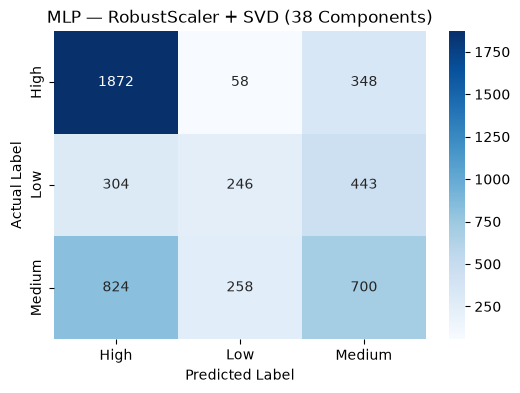

In [449]:
# Confusion matrix visualization

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_mlp_robust38,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('MLP — RobustScaler + SVD (38 Components)')
plt.show()

Key findings
- High severity: Correctly identified 1,872 of 2,278 claims (82.2%). It missed 406 High-severity claims, including 348 classified as Medium.
- Low severity: Correctly identified 246 of 993 claims (24.8%). Most errors involved predictions of Medium (443 claims).
- Medium severity: Correctly identified 700 of 1,782 claims (39.3%). The most common error was classifying them as High (824 claims).
Main concern: The model frequently predicts High for actual Medium claims. While this helps prioritize potentially serious claims, it can also lead to unnecessary prioritization.

## Classification Model Comparison — StandardScaler + SVD (38 Components)

The three classification models were evaluated using accuracy, Macro F1, and class-specific recall, with particular emphasis on detecting High-severity claims.

| Model | Accuracy | Macro F1 | High Recall | Medium Recall | Low Recall |
|---|---:|---:|---:|---:|---:|
| Random Forest | 53.77% | **48.53%** | 74% | 41% | 30% |
| XGBoost | 53.16% | 48.17% | 69% | **48%** | 27% |
| MLP | **55.77%** | 47.92% | **87%** | 31% | 28% |

**Key findings:**
- **High severity:** MLP achieved the highest recall at 87%, making it the strongest model for identifying High-severity claims.
- **Medium severity:** XGBoost performed best, with 48% recall.
- **Low severity:** Random Forest achieved the highest recall at 30%, although all three models struggled with this class.
- **Overall:** MLP achieved the highest accuracy, while Random Forest achieved the highest Macro F1.

These results suggest that MLP is the strongest candidate when missing High-severity claims is the primary concern, although its lower recall for Medium and Low claims remains a limitation.

## Classification Model Comparison — RobustScaler + SVD (38 Components)

| Model | Accuracy | Macro F1 | High Recall | Medium Recall | Low Recall |
|---|---:|---:|---:|---:|---:|
| Random Forest | 54.32% | 48.29% | 77% | 40% | 28% |
| XGBoost | 53.57% | 47.50% | 74% | 43% | 25% |
| MLP | **55.77%** | **48.45%** | **82%** | 39% | 25% |

**Key findings:**

- **High severity:** MLP achieved the highest recall at 82%, followed by Random Forest at 77% and XGBoost at 74%.
- **Medium severity:** XGBoost performed best, with 43% recall.
- **Low severity:** Random Forest performed best, with 28% recall.
- **Overall:** MLP achieved the highest accuracy (55.77%) and Macro F1 (48.45%).

MLP is the strongest candidate when prioritizing High-severity detection, while Random Forest performs better at identifying Low-severity claims. All three models still struggle to classify Low-severity claims accurately.

## Comparing StandardScaler and RobustScaler — SVD (38 Components)

The six experiments were compared using accuracy, Macro F1, and recall for High-, Medium-, and Low-severity claims.

| Model | Scaler | Accuracy | Macro F1 | High Recall | Medium Recall | Low Recall |
|---|---|---:|---:|---:|---:|---:|
| Random Forest | StandardScaler | 53.77% | **48.53%** | 74% | 41% | 30% |
| Random Forest | RobustScaler | **54.32%** | 48.29% | **77%** | 40% | 28% |
| XGBoost | StandardScaler | 53.16% | **48.17%** | 69% | **48%** | **27%** |
| XGBoost | RobustScaler | **53.57%** | 47.50% | **74%** | 43% | 25% |
| MLP | StandardScaler | **55.77%** | 47.92% | **87%** | 31% | **28%** |
| MLP | RobustScaler | **55.77%** | **48.45%** | 82% | **39%** | 25% |

### Key findings

- **High severity:** StandardScaler MLP achieved the highest recall at **87%**, compared with 82% for RobustScaler MLP. RobustScaler improved High recall for Random Forest and XGBoost.
- **Medium severity:** StandardScaler XGBoost achieved the highest recall at **48%**. RobustScaler improved MLP's Medium recall from 31% to 39%.
- **Low severity:** StandardScaler Random Forest achieved the highest recall at **30%**. StandardScaler also performed better for Low claims with XGBoost and MLP.
- **Accuracy:** MLP achieved the highest accuracy under both scalers at **55.77%**.
- **Macro F1:** RobustScaler MLP achieved the highest Macro F1 at **48.45%**, indicating slightly more balanced performance across the three classes than StandardScaler MLP.

### Conclusion

StandardScaler MLP is the strongest candidate if the main priority is detecting High-severity claims, achieving 87% recall. RobustScaler MLP offers a better balance across classes according to Macro F1 and improves Medium-severity recall.

Since this project prioritizes identifying High-severity insurance claims, **StandardScaler MLP is the leading candidate**, although its low recall for Low- and Medium-severity claims remains a limitation.

# **Error Analysis**

## Analyzing the missed High severityclaims in MLP standard scaler

In [450]:
#-----------------------------------
# Step 1: Separate the two groups
# -------------------------------- 

# High-severity claims correctly identified
correct_high = (
    (y_test == 'High') &
    (y_pred_mlp_standard38 == 'High')
)

# High-severity claims incorrectly classified as Low or Medium
missed_high = (
    (y_test == 'High') &
    (y_pred_mlp_standard38 != 'High')
)

print("Correctly detected High claims:", correct_high.sum())
print("Missed High claims:", missed_high.sum())

Correctly detected High claims: 1793
Missed High claims: 485


In [451]:
# Compare feature averages
# Get original test features for the two groups
correct_high_features = X_test.loc[correct_high]
missed_high_features = X_test.loc[missed_high]

# Compare average numeric feature values
feature_comparison = pd.DataFrame({
    'Correctly Detected High': correct_high_features.mean(numeric_only=True),
    'Missed High': missed_high_features.mean(numeric_only=True)
})

feature_comparison['Difference'] = (
    feature_comparison['Missed High'] -
    feature_comparison['Correctly Detected High']
)

display(feature_comparison.round(2))

,Correctly Detected High,Missed High,Difference
ReportingDelay,40.65,29.86,-10.79
AccidentHour,10.77,11.53,0.76
Age,39.96,31.96,-8.00
WeeklyRate,651.75,534.52,-117.23
HoursWorkedPerWeek,38.01,36.51,-1.50
DependentChildren,0.19,0.05,-0.13
DependentsOther,0.01,0.01,0.00
DaysWorkedPerWeek,4.91,4.87,-0.04
InitialCaseEstimate,22985.16,11269.34,-11715.83
AccidentYear,2003.78,2003.80,0.02


The missed High-severity claims tend to have lower average values for several features than the correctly detected High-severity claims.


The average original feature values were compared between the 1,984 correctly detected High-severity claims and the 294 High-severity claims misclassified as Low or Medium.

| Feature | Correctly Detected High | Missed High | Difference |
|---|---:|---:|---:|
| ReportingDelay | 39.71 | 29.21 | -10.49 |
| Age | 39.26 | 31.49 | -7.77 |
| WeeklyRate | 648.11 | 482.93 | -165.18 |
| HoursWorkedPerWeek | 37.91 | 36.22 | -1.69 |

**Key findings:**

- **WeeklyRate:** Missed High-severity claims had a lower average weekly rate by 165.18.
- **Age:** Claimants in the missed group were approximately 7.77 years younger on average.
- **ReportingDelay:** Missed claims had a lower average reporting delay by 10.49, assuming the variable is measured in days.
- **HoursWorkedPerWeek:** The missed group worked approximately 1.69 fewer hours per week on average.

These differences suggest that some missed High-severity claims may have feature patterns less readily recognized by the MLP. However, differences in averages alone do not establish the cause of misclassification.

**Note:** `InitialCaseEstimate` was excluded from the model inputs to prevent potential target leakage. Although its average was substantially lower in the missed group, it should not be used to explain the model's predictions because the model did not use it.

## Analyze the claim-description keywords

In [452]:
# Get original claim descriptions for High-severity claims
correct_high_descriptions = df.loc[
    correct_high.index[correct_high],
    'ClaimDescription'
]

missed_high_descriptions = df.loc[
    missed_high.index[missed_high],
    'ClaimDescription'
]

print("Correctly detected High claims:")
display(correct_high_descriptions.head())

print("\nMissed High claims:")
display(missed_high_descriptions.head())

Correctly detected High claims:


2     SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...
24                 SLIPPED ON WET FLOOR LEFT LOWER BACK
31                   MOVING FURNITURE LOWER BACK STRAIN
36    STRUCK PALLET SOFT TISSUE INJURY TO LEFT THUMB...
38         LIFTING BED STRAINED NECK STRAIN RIGHT WRIST
Name: ClaimDescription, dtype: str


Missed High claims:


15              FELL DOWN LOWER BACK STRAIN LOWER BACK
101       STRUCK WITH WOOD LACERATED LEFT INDEX FINGER
134                  STRUCK DUST FOREIGN BODY LEFT EYE
145    LIFTING BRICKS TENDONITIS RIGHT SHOULDER STRAIN
235                     LIFTING TIMBER FRACTURED WRIST
Name: ClaimDescription, dtype: str

**Correctly Detected vs. Missed High-Severity Claims**

A sample of claim descriptions was examined for correctly detected and missed High-severity claims. Both groups contain descriptions involving injuries such as strains, lacerations, and impacts.

The sample suggests that the wording of a claim description alone may not clearly distinguish High-severity claims from other severity levels. However, these examples are not sufficient to establish which keywords contribute to misclassification.

In [453]:
# Compare most frequent word
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

vectorizer = CountVectorizer(stop_words='english', max_features=15)

correct_word_counts = vectorizer.fit_transform(
    correct_high_descriptions.fillna('')
)

correct_words = pd.Series(
    correct_word_counts.toarray().sum(axis=0),
    index=vectorizer.get_feature_names_out()
).sort_values(ascending=False)

vectorizer_missed = CountVectorizer(stop_words='english', max_features=15)

missed_word_counts = vectorizer_missed.fit_transform(
    missed_high_descriptions.fillna('')
)

missed_words = pd.Series(
    missed_word_counts.toarray().sum(axis=0),
    index=vectorizer_missed.get_feature_names_out()
).sort_values(ascending=False)

print("Most frequent words — Correctly detected High claims:")
display(correct_words)

print("Most frequent words — Missed High claims:")
display(missed_words)

Most frequent words — Correctly detected High claims:


strain      1690
lower        822
lifting      766
right        683
left         458
shoulder     401
injury       258
struck       255
fell         241
slipped      231
knee         225
wrist        117
neck         113
strained     111
boxes        106
dtype: int64

Most frequent words — Missed High claims:


left          279
right         262
struck        236
laceration    160
knife         137
strain        132
finger        116
hand           92
lacerated      88
thumb          75
lifting        72
slipped        50
metal          50
index          47
shoulder       47
dtype: int64

The results suggest that the correctly detected and missed High-severity claims have different word patterns.
Interpretation
- Correctly detected High claims: The most frequent words are strain, lower, lifting, shoulder, and injury. This group contains many descriptions involving strains and injuries to areas such as the lower back and shoulder.
- Missed High claims: The most frequent words are left, struck, laceration, knife, and finger. These descriptions more often mention cuts, impacts, and injuries to the hands and fingers.
- Shared words: Both groups contain terms such as left, right, strain, and lifting, meaning that some injury descriptions overlap between the groups.

The difference suggests that the model may be handling some injury-description patterns better than others. However, word frequency alone cannot establish why claims were misclassified. The severity labels were derived from Incurred, so injury wording does not necessarily correspond directly to the assigned severity.

In [454]:
# compare word frequencies using the same vocabulary for both groups.
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Combine descriptions so both groups use the same vocabulary
all_descriptions = pd.concat([
    correct_high_descriptions.fillna(''),
    missed_high_descriptions.fillna('')
])

vectorizer = CountVectorizer(stop_words='english', max_features=30)
word_matrix = vectorizer.fit_transform(all_descriptions)

# Separate word counts for each group
n_correct = len(correct_high_descriptions)
correct_counts = word_matrix[:n_correct].toarray().sum(axis=0)
missed_counts = word_matrix[n_correct:].toarray().sum(axis=0)

word_comparison = pd.DataFrame({
    'Word': vectorizer.get_feature_names_out(),
    'Correct High': correct_counts,
    'Missed High': missed_counts
})

# Compare proportions because the groups have different sizes
word_comparison['Correct %'] = (
    word_comparison['Correct High'] / len(correct_high_descriptions) * 100
)
word_comparison['Missed %'] = (
    word_comparison['Missed High'] / len(missed_high_descriptions) * 100
)

word_comparison['Difference (percentage points)'] = (
    word_comparison['Missed %'] - word_comparison['Correct %']
)

display(
    word_comparison.sort_values(
        'Difference (percentage points)', ascending=False
    ).round(2)
)

,Word,Correct High,Missed High,Correct %,Missed %,Difference (percentage points)
25,struck,255,236,14.22,48.66,34.44
12,left,458,279,25.54,57.53,31.98
10,laceration,94,160,5.24,32.99,27.75
8,knife,51,137,2.84,28.25,25.40
3,finger,83,116,4.63,23.92,19.29
18,right,683,262,38.09,54.02,15.93
9,lacerated,54,88,3.01,18.14,15.13
5,hand,87,92,4.85,18.97,14.12
26,thumb,48,75,2.68,15.46,12.79
15,metal,54,50,3.01,10.31,7.30


These results show clearer differences between the descriptions of correctly detected and missed High-severity claims.
Interpretation
- Words more common in missed claims: struck (+40.47 percentage points), left (+37.84), laceration (+36.01), and knife (+35.44). These terms are much more prevalent in the descriptions of missed High claims.
- Words more common in correctly detected claims: strain (75.04 percentage points higher), lower (40.16), lifting (29.74), and shoulder (17.50). The model appears to detect High claims more successfully when descriptions contain these patterns.
- Possible explanation: The model may be better at recognizing common strain-related descriptions than descriptions involving cuts, knives, or finger injuries. However, this is a hypothesis, not proof that these words caused the errors.

**NB:** results already suggest that strain-related descriptions are more common among correctly detected High claims, while laceration-related descriptions are more common among missed High claims.

One important limitation: the percentages represent the proportion of descriptions containing each word, not the probability that a claim is High severity. Also, the top 30 words were selected from the combined groups, so this is a descriptive comparison rather than a complete analysis of all claim vocabulary.

# **Final Model Evaluation**

Three classification algorithms—Random Forest, XGBoost, and Multi-Layer Perceptron (MLP)—were evaluated using StandardScaler and RobustScaler, with TruncatedSVD reducing the combined structured and TF-IDF feature space to 38 components.

The models were compared using accuracy, macro F1-score, and recall for each severity class. Since failing to identify a High-severity claim may have serious consequences, High-severity recall was given particular importance.

The StandardScaler MLP achieved **55.77% accuracy** and **87% High-severity recall**, correctly identifying approximately 87% of actual High-severity claims. However, its recall for Medium and Low claims was approximately 31% and 28%, respectively.

The RobustScaler MLP achieved the same accuracy of **55.77%**, a slightly higher macro F1-score of **48.45%**, and High-severity recall of approximately **82%**. It also performed better at identifying Medium claims, with recall of approximately 39%.

The results reveal a trade-off between detecting High-severity claims and achieving more balanced performance across all classes. The StandardScaler MLP is preferred when prioritizing High-severity detection, while the RobustScaler MLP offers a slightly more balanced classification performance.

Despite these results, neither model performs strongly across all three classes. The models' predictions should therefore support, rather than replace, human review of insurance claims.

# **Conclusion and Limitations**

This project developed a machine learning approach for classifying insurance claims into Low, Medium, and High severity categories using structured claim information and text features extracted from claim descriptions. TF-IDF was used to represent claim-description keywords, while TruncatedSVD reduced the dimensionality of the combined feature space.

The experiments demonstrated that the MLP achieved the highest observed High-severity recall among the evaluated configurations when using StandardScaler, correctly identifying approximately 87% of actual High-severity claims. However, the model struggled to distinguish Low- and Medium-severity claims, highlighting the difficulty of achieving balanced performance across all classes.

Error analysis showed that correctly detected High-severity claims more frequently contained terms such as *strain*, *lower*, and *lifting*, whereas missed High-severity claims more frequently contained terms such as *laceration*, *knife*, and *struck*. These findings suggest differences in claim-description patterns between the two groups, although they do not establish the causes of misclassification.

Several limitations should be considered. The classification models did not perform equally well across all severity classes, and the keyword analysis was exploratory. Furthermore, the dataset was divided chronologically, so performance on future claims may differ from the results observed in the test set.

Overall, the project demonstrates the potential of combining structured insurance data and text-based features for automated claims triage. However, further validation and model improvement are necessary before deployment. In practice, the model could help prioritize claims for human assessment, with particular attention given to claims that may be incorrectly classified as Low or Medium severity.

## Investigating why all models struggle in detecting low and medium claims

In [455]:
# Select numerical features from the original training data
numeric_cols = model_df.select_dtypes(include="number").columns.tolist()

# Exclude columns that should not be model inputs
numeric_cols = [
    col for col in numeric_cols
    if col not in ["Incurred", "InitialCaseEstimate"]
]

# Get training rows using your chronological split
train_data = model_df.loc[train_mask].copy()

# Compare median values across severity classes
severity_comparison = train_data.groupby("Severity")[numeric_cols].median().T

# Measure the absolute difference between Low and Medium medians
severity_comparison["Low-Medium Difference"] = (
    severity_comparison["Low"] - severity_comparison["Medium"]
).abs()

severity_comparison.sort_values(
    "Low-Medium Difference", ascending=False
).round(2)

Severity,High,Low,Medium,Low-Medium Difference
WeeklyRate,387.5,200.0,299.15,99.15
Age,36.0,28.0,31.00,3.00
ReportingDelay,22.0,24.0,23.00,1.00
AccidentHour,11.0,11.0,11.00,0.00
HoursWorkedPerWeek,38.0,38.0,38.00,0.00
DependentChildren,0.0,0.0,0.00,0.00
DependentsOther,0.0,0.0,0.00,0.00
DaysWorkedPerWeek,5.0,5.0,5.00,0.00


The numerical feature analysis compared the median values of each numerical feature across Low, Medium and High severity claims to investigate whether these features could help distinguish between the severity classes.

- **WeeklyRate:** Low claims had a median of 200.00, while Medium claims had a median of 299.15, giving an absolute difference of 99.15. This suggests that WeeklyRate may help distinguish the two classes, although the difference alone does not establish how accurately it can separate individual claims.

- **Age:** Low claims had a median age of 28 years, compared with 31 years for Medium claims, a difference of 3 years. This relatively small difference suggests that age alone may provide limited information for distinguishing these classes.

- **ReportingDelay:** The median was 24 days for Low claims and 23 days for Medium claims, a difference of only one day. This indicates that the typical reporting delay is very similar between the two classes.

- **AccidentHour and HoursWorkedPerWeek:** Both classes had identical medians of 11 hours and 38 hours per week, respectively. These identical medians indicate that the typical values of these features do not distinguish Low from Medium claims.

- **DependentChildren, DependentsOther, and DaysWorkedPerWeek:** These features also had identical medians across the classes, meaning their median values provide no clear distinction between Low and Medium claims.


**Conclusion:** The results suggest that several numerical features have similar typical values for Low and Medium claims. When features do not clearly separate these classes, models may find it difficult to learn decision boundaries that reliably distinguish them. This could partly explain why Random Forest, XGBoost and the MLP struggled to identify Low and Medium claims.

In [456]:
# Investigating claim descriptions
from sklearn.feature_extraction.text import CountVectorizer

# Use the original training claim descriptions
text_data = model_df.loc[train_mask, "ClaimDescription_Stemmed"]

# Convert descriptions into word counts
vectorizer = CountVectorizer(max_features=1000, stop_words="english")
X_words = vectorizer.fit_transform(text_data)

# Calculate average word frequency by severity class
word_df = pd.DataFrame(
    X_words.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=text_data.index
)

word_df["Severity"] = model_df.loc[train_mask, "Severity"]

word_means = word_df.groupby("Severity").mean().T

# Find words with the greatest frequency differences
word_means["High_vs_LowMedium"] = (
    word_means["High"] -
    (word_means["Low"] + word_means["Medium"]) / 2
)

word_means.sort_values(
    "High_vs_LowMedium", ascending=False
).head(15).round(4)

Severity,High,Low,Medium,High_vs_LowMedium
strain,0.7821,0.2377,0.4780,0.4242
lower,0.4531,0.0892,0.2330,0.2920
lift,0.3735,0.1465,0.2337,0.1834
shoulder,0.1863,0.0799,0.1313,0.0808
injuri,0.1578,0.0596,0.1053,0.0754
pain,0.0628,0.0094,0.0301,0.0430
fall,0.1945,0.1362,0.1757,0.0386
box,0.0809,0.0336,0.0523,0.0379
neck,0.0733,0.0240,0.0510,0.0357
ladder,0.0558,0.0278,0.0390,0.0224


The claim-description analysis compared average word frequencies in Low- and Medium-severity claims to investigate why the models struggled to distinguish between these classes.

- **Strain:** This word appeared more frequently in Medium claims (0.4780) than Low claims (0.2377). This difference may help distinguish some Medium claims from Low claims, although the word also appears in High-severity claims.

- **Lower and lift:** Both words occurred more frequently in Medium claims than Low claims. For *lower*, the average frequencies were 0.2330 for Medium and 0.0892 for Low; for *lift*, they were 0.2337 and 0.1465, respectively. These differences suggest that the words may provide some useful information, but they do not necessarily separate individual claims reliably.

- **Shoulder and injury:** These words were also more frequent in Medium claims (0.1313 and 0.1053) than Low claims (0.0799 and 0.0596). Their presence in both classes, however, limits their usefulness as standalone indicators.

- **Fall:** The average frequencies were relatively close: 0.1757 for Medium claims and 0.1362 for Low claims. This smaller difference suggests that the word may offer limited information for separating the two classes by itself.

- **Pain, box, neck, ladder, floor, fracture, soft, and tissue:** These terms generally appeared more frequently in Medium claims than Low claims, but the differences varied. Their presence in both classes means they cannot independently establish a claim's severity.

- **Knee:** This word appeared slightly more frequently in Medium claims (0.1073) than Low claims (0.0708). However, its frequency in High claims (0.1045) was also similar to Medium, so it may be less useful for distinguishing Medium claims from both other classes.


**Conclusion:** The results show that several words occur more frequently in Medium claims than Low claims, but the two classes share much of the same vocabulary. This overlap may make it difficult for models to establish reliable boundaries between them, particularly when a claim contains words associated with multiple severity categories.